# Installs and imports

In [1]:
# !pip install matplotlib==3.1.3

In [2]:
# !pip install xgboost=='1.6.0'

In [3]:
# !pip install catboost

In [4]:
import matplotlib
import xgboost
import catboost
print(matplotlib.__version__, " ", xgboost.__version__, " ", catboost.__version__)

3.11.2   1.6.0   1.2.10


In [5]:
import os
import pandas as pd
import numpy as np
import datetime
import json
import joblib
import pickle

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import mean_squared_error, accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, PrecisionRecallDisplay
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from xgboost import XGBClassifier, plot_importance
from catboost import CatBoostClassifier
from sklearn.model_selection import cross_val_score
from hyperopt import hp, tpe
from hyperopt.fmin import fmin

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

%matplotlib inline

SEED = 42


# Useful functions

## Plot feature importance

In [6]:
def plot_feature_importance(importance, names, model_type, figsize=(10, 5), n=20):
    
    #Create arrays from feature importance and feature names
    feature_importance = np.array(importance)
    abs_importance = np.abs(feature_importance)
    feature_names = []
    for name in names:
        feature_names.append(features_dict[name]['en'])
    feature_names = np.array(feature_names)
    
    #Create a DataFrame using a Dictionary
    data={'feature_names': feature_names,
          'feature_importance':feature_importance,
          'abs_importance': abs_importance}
    fi_df = pd.DataFrame(data)
    
    #Sort the DataFrame in order decreasing feature importance
    fi_df.sort_values(by=['abs_importance'], ascending=False, inplace=True)
    fi_df = fi_df.head(n)
    
    #Define size of bar plot
    plt.figure(figsize=figsize)
    #Plot Searborn bar chart
    sns.barplot(x=fi_df['feature_importance'], y=fi_df['feature_names'])
    #Add chart labels
    plt.tick_params(labelsize=14)
    #plt.title(model_type + 'FEATURE IMPORTANCE')
    plt.xlabel('FEATURE IMPORTANCE')#, fontsize=14)
    plt.ylabel('FEATURE NAMES')#, fontsize=14)

## Pick XGBoost hyperparameters

In [7]:
def hyperopt_xgb_score(params):
    clf = XGBClassifier(**params)
    # усреднение по трем фолдам, для уменьшения влияния стахостичности
    # для ускорения можно использовать train_test_split один раз
    current_score = cross_val_score(clf, X, y, cv=StratifiedKFold(n_splits=3), scoring='accuracy').mean()
    print(current_score, params)
    return -current_score

## Find difference between feature presence and feature absence

In [8]:
def find_diff(model, client, feature):
    '''
    returns average of differences between model prediction
    with specified featrue set to 1
    and same model predictions for the same feature
    set to zero and set to nan
    '''
    client_ = client.copy()
    if feature == 'age': # numerical feature, has negative correlation with result
        return -1
    if feature == 'disability_group': # ordinal feature, has positive correlation with result
        return 1
    #client_[feature] = np.nan
    #with_nan = model.predict_proba(client_)[0, 1] # model prediction for nan case
    client_[feature] = 1
    with_one = model.predict_proba(client_)[0, 1] # model prediction for one case
    client_[feature] = 0
    with_zero = model.predict_proba(client_)[0, 1] # model prediction for zero case
    return (with_one - with_zero)

## Find both-ways most significant features for specific client

In [9]:
def find_important_features(model, client, n = 20, figsize=(12, 8)):
    '''
    returns top N most important features
    that are currently unknown (NaN)
    for specific client feature set
    '''
    unknown_features = client.columns[client.isna().any()].tolist()
    diffs = []
    for feature in unknown_features:
        diffs.append(find_diff(model, client, feature))
    data={'feature_names': unknown_features, 'feature_importance': diffs}
    fi_df = pd.DataFrame(data)
    fi_df.sort_values(by='feature_importance', key=abs, ascending=False, inplace=True)
    fi_df = fi_df.head(n)
    
    #Define size of bar plot
    plt.figure(figsize=figsize)
    
    #Plot Searborn bar chart
    sns.barplot(x=fi_df['feature_importance'], y=fi_df['feature_names'])
    
    #Add chart labels
    plt.tick_params(labelsize=12)
    plt.title('FEATURES TO CARE ABOUT')
    plt.xlabel('FEATURE IMPORTANCE')#, fontsize=14)
    plt.ylabel('FEATURE NAMES')#, fontsize=14)

## Get signs for feature importances

In [10]:
def get_signs (model, features):
    corrs = []
    result = []
    for feature in features:
        corr = xy_t.corr().contract_success[feature]
        corrs.append(corr)
    result = np.sign(corrs)
    return result

## Get and plot both-way feature importance (top N features)

In [11]:
def plot_icicle(model, features, fi_method_result):
    signed_importances = fi_method_result * get_signs(model, features)
    plot_feature_importance(signed_importances, features, "")

## Dictionary to make features readable

In [12]:
features_dict = {
    'type_1': {'ru': 'тип 1 Паспорт', 'en': 'type 1 Passport'},
    'type_2': {'ru': 'тип 2 Пенсия: оформление', 'en': 'type 2 Soc. benefits'},
    'type_3': {'ru': 'тип 3 Полис ОМС', 'en': 'type 3 Med. insurance'},
    'type_4': {'ru': 'тип 4 ИНН', 'en': 'type 4 Taxpayer ID'},
    'type_5': {'ru': 'тип 5 Трудовой стаж', 'en': 'type 5 Work experience'},
    'type_6': {'ru': 'тип 6 Инвалидность', 'en': 'type 6 Disability'},
    'type_7': {'ru': 'тип 7 Интернат', 'en': 'type 7 Nursinghome'},
    'type_8': {'ru': 'тип 8 Временная регистрация', 'en': 'type 8 Temp. registration'},
    'type_9': {'ru': 'тип 9 Регистрация по др. адресу', 'en': 'type 9 Registration at other address'},
    'type_10': {'ru': 'тип 10 Трудоустройство', 'en': 'type 10 Employment'},
    'type_11': {'ru': 'тип 11 Трудоустройство с проживанием', 'en': 'type 11 Employment with Accommodation'},
    'type_12': {'ru': 'тип 12 ДНП', 'en': 'type 12 Night Shelter'},
    'type_13': {'ru': 'тип 13 Реаб. центры алко/нарко', 'en': 'type 13 Rehab centers, alco/chem'},
    'type_14': {'ru': 'тип 14 Больница', 'en': 'type 14 Hospital'},
    'type_15': {'ru': 'тип 15 Поиск родственников', 'en': 'type 15 Relatives search'},
    'type_16': {'ru': 'тип 16 Возвращение в др. город', 'en': 'type 16 Return to other city'},
    'type_17': {'ru': 'тип 17 Гражданство', 'en': 'type 17 Citizenship'},
    'type_18': {'ru': 'тип 18 Юр. сопровождение в суде', 'en': 'type 18 Legal support in court'},
    'type_19': {'ru': 'тип 19 Жилье', 'en': 'type 19 Accommodation'},
    'type_20': {'ru': 'тип 20 Отмена мошеннической сделки, возврат жилья', 'en': 'type 20 Cancel fraudulent transaction, return housing'},
    'type_21': {'ru': 'тип 21 Запросы, заявления', 'en': 'type 21 Requests, aplications'},
    'type_22': {'ru': 'тип 22 Дом на полдороги', 'en': 'type 22 Halfway House project'},
    'type_23': {'ru': 'тип 23 Документы об образовании', 'en': 'type 23 Education documents'},
    'type_24': {'ru': 'тип 24 Свидетельство о рождении', 'en': 'type 24 Birth Certificate'},
    'type_25': {'ru': 'тип 25 Военный билет', 'en': 'type 25 Military Service Card'},
    'type_26': {'ru': 'тип 26 Загранпаспорт', 'en': 'type 26 Travel Passport'},
    'type_27': {'ru': 'тип 27 Тех. средства реабилитации', 'en': 'type 27 Technical rehabilitation equipment'},
    'type_28': {'ru': 'тип 28 СНИЛС', 'en': 'type 28 Individual Insurance Account Number'},
    'type_29': {'ru': 'тип 29 ЦСА', 'en': 'type 29 Social Adaptation Center'},
    'type_30': {'ru': 'тип 30 Проф. обучение', 'en': 'type 30 Proffessional Training'},
    'type_31': {'ru': 'тип 31 Установление личности', 'en': 'type 31 Identification'},
    'type_32': {'ru': 'тип 32 СПИД-центр: постановка на учет', 'en': 'type 32 AIDS center: registration'},
    'type_33': {'ru': 'тип 33 Кризисный центр', 'en': 'type 33 Crisis center'},
    'type_34': {'ru': 'тип 34 Психологическое сопровождение', 'en': 'type 34 Psychological support'},
    'type_35': {'ru': 'тип 35 Пенсия: перерасчет, возобновление', 'en': 'type 35 Soc. benefits: recalculation, renewal'},
    'type_36': {'ru': 'тип 36 Гражданский суд: доведение дела', 'en': 'type 36 Bringing case to Civil Court'},
    'type_37': {'ru': 'тип 37 Зарплата: получение', 'en': 'type 37 Payroll receipt'},
    'type_38': {'ru': 'тип 38 Восстановление здоровья', 'en': 'type 38 Health restoration'},
    'type_39': {'ru': 'тип 39 Адаптационная программа по трудоустройству', 'en': 'type 39 Empolyment Adaptation Program'},
    'type_40': {'ru': 'тип 40 Поддерживаемое проживание', 'en': 'type 40 Supported living'},
    'type_41': {'ru': 'тип 41 Сопровождение клиентов РП с химзависимостью', 'en': 'type 41 Support of clients with chem. addiction'},
    'type_42': {'ru': 'тип 42 Подготовка к заселению в ДНПД', 'en': 'type 42 Preparation for Halfway House accommodation'},
    'type_43': {'ru': 'тип 43 Хостел', 'en': 'type 43 Hostel'},
    'gender': {'ru': 'Мужской пол', 'en': 'Male'},
    'age': {'ru': 'Возраст', 'en': 'Age'},
    'no_birthdate': {'ru': 'Неизвестна дата рождения', 'en': 'Birthdate unknown'},
    'is_homeless': {'ru': 'Бездомный', 'en': 'Homeless'},
    'is_married': {'ru': 'Состоит в браке', 'en': 'Married'},
    'has_dependants': {'ru': 'Имеет родственников на попечении', 'en': 'Has dependants'},
    'has_profession': {'ru': 'Имеет профессию', 'en': 'Has profession'},
    'has_residence': {'ru': 'Имеет жилое помещение', 'en': 'Has residence'},
    'contacts_relatives': {'ru': 'Поддерживает контакты с родственниками', 'en': 'Contacts relatives'},
    'no_relatives': {'ru': 'Нет родственников', 'en': 'No relatives'},
    'source_perm_job': {'ru': 'Осн. источник средств - постоянная работа', 'en': 'Primary source of income is permanent job'},
    'source_temp_job': {'ru': 'Осн. источник средств - временная работа', 'en': 'Primary source of income is temporary job'},
    'source_alms': {'ru': 'Осн. источник средств - подаяния', 'en': 'Primary source of income is alms'},
    'source_relatives': {'ru': 'Осн. источник средств - поддержка родственниками', 'en': 'Primary source of income is support by relatives'},
    'source_other': {'ru': 'Осн. источник средств - прочее', 'en': 'Other primary source of income'},
    'source_gathering': {'ru': 'Осн. источник средств - собирательство', 'en': 'Primary source of income is gathering'},
    'source_charity': {'ru': 'Осн. источник средств - благотворительность', 'en': 'Primary source of income is charity'},
    'source_rehabs': {'ru': 'Осн. источник средств - реаб. центры', 'en': 'Primary source of income is rehab centers'},
    'source_social_benefits': {'ru': 'Осн. источник средств - пенсия', 'en': 'Primary source of income is social benefits'},
    'is_citizen': {'ru': 'Гражданин РФ', 'en': 'Has citizenship'},
    'is_retired': {'ru': 'Пенсионер', 'en': 'Retired'},
    'disability_group': {'ru': 'Группа инвалидности', 'en': 'Disability group'},
    'is_registered': {'ru': 'Есть регистрация', 'en': 'Registered'},
    'from_orphanage': {'ru': 'Выпускник детдома', 'en': 'From orphanage'},
    'was_confined': {'ru': 'Был в МЛС', 'en': 'Was confined'},
    'comments_alcohol': {'ru': 'Комментарии: проблемы с алкоголем', 'en': 'Comments: alcohol'},
    'comments_chem': {'ru': 'Комментарии: наркотики, химзависимость', 'en': 'Comments: narco or chemical addiction'},
    'comments_disability': {'ru': 'Комментарии: инвалидность', 'en': 'Comments: disability'},
    'comments_absence': {'ru': 'Комментарии: неявка', 'en': 'Comments: absence'},
    'comments_orphange': {'ru': 'Комментарии: детдом', 'en': 'Comments: orphanage'},
    'comments_work': {'ru': 'Комментарии: поиски работы', 'en': 'Comments: looking for job'},
    'comments_confinement': {'ru': 'Комментарии: МЛС', 'en': 'Comments: confinement'},
    'comments_noresidence': {'ru': 'Комментарии: отсутствие жилья', 'en': 'Comments: no residence'},
    'comments_aggression': {'ru': 'Комментарии: агрессивное поведение', 'en': 'Comments: aggressive behavior'},
    'comments_disturbance': {'ru': 'Комментарии: нарушение режима', 'en': 'Comments: disturbance'},
    'comments_disease': {'ru': 'Комментарии: болезнь', 'en': 'Comments disease'},
    'comments_death': {'ru': 'Комментарии: смерть клиента или близких', 'en': 'Comments: client\'s or relative\'s death'},
    'comments_nursinghome': {'ru': 'Комментарии: интернат', 'en': 'Comments: nursinghome'},
    'comments_relatives': {'ru': 'Комментарии: родственники', 'en': 'Comments: relatives'},
    'comments_illiteracy': {'ru': 'Комментарии: неграмотность', 'en': 'Comments: illiteracy'},
    'comments_foreigner': {'ru': 'Комментарии: иностранный гражданин', 'en': 'Comments: foreign citizen'},
    'comments_ticket': {'ru': 'Комментарии: нужен билет', 'en': 'Comments: ticket needed'},
    'comments_court': {'ru': 'Комментарии: судебное разбирательство', 'en': 'Comments: court'},
    'comments_pregnancy': {'ru': 'Комментарии: беременность', 'en': 'Comments: pregnancy'},
    'comments_mental': {'ru': 'Комментарии: проблемы с психикой', 'en': 'Comments: mental problems'},
    'comments_fire': {'ru': 'Комментарии: сгоревшее жилье', 'en': 'Comments: fire in residence'},
    'comments_social_benefits': {'ru': 'Комментарии: пенсия', 'en': 'Comments: social benefits'},
    'comments_divorce': {'ru': 'Комментарии: развод', 'en': 'Comments: divorce'},
    'released_recently': {'ru': 'Недавно освободился из МЛС', 'en': 'Comments: released recently'},
    'chem_confirmed': {'ru': 'Хим. завимость подтверждена', 'en': 'Chem. addiction confirmed'},
    'chem_possible': {'ru': 'Хим. зависимость возможна', 'en': 'Chem. addiction possible'},
    'chem_noanswer': {'ru': 'Хим зависимость - отказ от ответа', 'en': 'Chem. addicition - refused to answer'},
    'chem_no': {'ru': 'Хим. зависимость отрицает', 'en': 'Denies chem. addiction'}
}

# Data download

In [13]:
with_onehot_types = pd.read_csv('final_with_onehot_types_ALL_221120.csv')
with_onehot_types.columns

Out[13]: 
Index(['contract_id', 'client_id', 'gender', 'age', 'no_birthdate',
       'is_homeless', 'is_married', 'has_dependants', 'has_profession',
       'has_residence', 'contract_status_id', 'contract_success',
       'comments_alcohol', 'comments_chem', 'comments_disability',
       'comments_absence', 'comments_orphange', 'comments_work',
       'comments_confinement', 'comments_noresidence', 'comments_aggression',
       'comments_disturbance', 'comments_disease', 'comments_death',
       'comments_nursinghome', 'comments_relatives', 'comments_illiteracy',
       'comments_foreigner', 'comments_ticket', 'comments_court',
       'comments_pregnancy', 'comments_mental', 'comments_fire',
       'comments_social_benefits', 'comments_divorce', 'contacts_relatives',
       'no_relatives', 'source_perm_job', 'source_temp_job',
       'source_social_benefits', 'source_alms', 'source_relatives',
       'source_other', 'source_gathering', 'source_charity', 'source_rehabs',
       'is_cit

Index(['contract_id', 'client_id', 'gender', 'age', 'no_birthdate',
       'is_homeless', 'is_married', 'has_dependants', 'has_profession',
       'has_residence', 'contract_status_id', 'contract_success',
       'comments_alcohol', 'comments_chem', 'comments_disability',
       'comments_absence', 'comments_orphange', 'comments_work',
       'comments_confinement', 'comments_noresidence', 'comments_aggression',
       'comments_disturbance', 'comments_disease', 'comments_death',
       'comments_nursinghome', 'comments_relatives', 'comments_illiteracy',
       'comments_foreigner', 'comments_ticket', 'comments_court',
       'comments_pregnancy', 'comments_mental', 'comments_fire',
       'comments_social_benefits', 'comments_divorce', 'contacts_relatives',
       'no_relatives', 'source_perm_job', 'source_temp_job',
       'source_social_benefits', 'source_alms', 'source_relatives',
       'source_other', 'source_gathering', 'source_charity', 'source_rehabs',
       'is_citizen', 'is

In [14]:
with_onehot_types.head()

Out[14]: 
   contract_id  client_id  gender  ...  type_41  type_42  type_43
0          583          1       1  ...        0        0        0
1          207          3       1  ...        0        0        0
2           22          9       1  ...        0        0        0
3         1067         10       1  ...        0        0        0
4         1067         10       1  ...        0        0        0

[5 rows x 100 columns]


,contract_id,client_id,gender,age,no_birthdate,is_homeless,is_married,has_dependants,has_profession,has_residence,contract_status_id,contract_success,comments_alcohol,comments_chem,comments_disability,comments_absence,comments_orphange,comments_work,comments_confinement,comments_noresidence,comments_aggression,comments_disturbance,comments_disease,comments_death,comments_nursinghome,comments_relatives,comments_illiteracy,comments_foreigner,comments_ticket,comments_court,comments_pregnancy,comments_mental,comments_fire,comments_social_benefits,comments_divorce,contacts_relatives,no_relatives,source_perm_job,source_temp_job,source_social_benefits,...,type_4,type_5,type_6,type_7,type_8,type_9,type_10,type_11,type_12,type_13,type_14,type_15,type_16,type_17,type_18,type_19,type_20,type_21,type_22,type_23,type_24,type_25,type_26,type_27,type_28,type_29,type_30,type_31,type_32,type_33,type_34,type_35,type_36,type_37,type_38,type_39,type_40,type_41,type_42,type_43
0,583,1,1,59.067606,0,1,1.0,1.0,NaN,0.0,2,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,NaN,NaN,NaN,...,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,207,3,1,60.535124,0,1,0.0,1.0,NaN,0.0,2,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,...,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,22,9,1,74.399885,0,1,0.0,0.0,NaN,0.0,6,0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1067,10,1,82.764191,0,1,0.0,1.0,NaN,0.0,7,0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,1067,10,1,82.764191,0,1,0.0,1.0,NaN,0.0,7,0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


subset is what experiments in the paper were made at: unsuccessful results are only those directly related to client's behavour.

In [15]:
subset = with_onehot_types[with_onehot_types.contract_status_id.isin([2, 3, 5, 7, 8])]
subset.info()

<class 'pandas.DataFrame'>
Index: 6349 entries, 0 to 8530
Data columns (total 100 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   contract_id               6349 non-null   int64  
 1   client_id                 6349 non-null   int64  
 2   gender                    6349 non-null   int64  
 3   age                       6347 non-null   float64
 4   no_birthdate              6349 non-null   int64  
 5   is_homeless               6349 non-null   int64  
 6   is_married                5528 non-null   float64
 7   has_dependants            5516 non-null   float64
 8   has_profession            2086 non-null   float64
 9   has_residence             5443 non-null   float64
 10  contract_status_id        6349 non-null   int64  
 11  contract_success          6349 non-null   int64  
 12  comments_alcohol          6093 non-null   float64
 13  comments_chem             6093 non-null   float64
 14  comments_disability    

# ML

## Test and validation sets

In [16]:
x_columns_t = [c for c in subset.columns if c not in ['contract_id', 'client_id', 'contract_success', 'contract_status_id']]
xy_columns_t = x_columns_t + ['contract_success']
X_t = subset[x_columns_t]
y_t = subset.contract_success
xy_t = subset[xy_columns_t]

In [17]:
X_train_t, X_val_t, y_train_t, y_val_t = train_test_split(X_t,
                                                          y_t,
                                                          test_size=0.2,
                                                          random_state=SEED,
                                                          stratify=y_t)
X_train_t.shape, X_val_t.shape, y_train_t.shape, y_val_t.shape

Out[17]: ((5079, 96), (1270, 96), (5079,), (1270,))


((5079, 96), (1270, 96), (5079,), (1270,))

In [18]:
rus = RandomUnderSampler(random_state=SEED)
X_res_train_t, y_res_train_t = rus.fit_resample(X_train_t, y_train_t)
X_res_train_t.shape, y_res_train_t.shape

Out[18]: ((3568, 96), (3568,))


((3568, 96), (3568,))

In [19]:
ros = RandomOverSampler(random_state=SEED)
X_ros_train_t, y_ros_train_t = ros.fit_resample(X_train_t, y_train_t)
X_ros_train_t.shape, y_ros_train_t.shape

Out[19]: ((6590, 96), (6590,))


((6590, 96), (6590,))

## Process NaNs for models that don't eat NaNs

Columns with NaNs

In [20]:
nan_columns = X_t.columns[X_t.isna().any()].tolist()
nan_columns

Out[20]: 
['age',
 'is_married',
 'has_dependants',
 'has_profession',
 'has_residence',
 'comments_alcohol',
 'comments_chem',
 'comments_disability',
 'comments_absence',
 'comments_orphange',
 'comments_work',
 'comments_confinement',
 'comments_noresidence',
 'comments_aggression',
 'comments_disturbance',
 'comments_disease',
 'comments_death',
 'comments_nursinghome',
 'comments_relatives',
 'comments_illiteracy',
 'comments_foreigner',
 'comments_ticket',
 'comments_court',
 'comments_pregnancy',
 'comments_mental',
 'comments_fire',
 'comments_social_benefits',
 'comments_divorce',
 'contacts_relatives',
 'no_relatives',
 'source_perm_job',
 'source_temp_job',
 'source_social_benefits',
 'source_alms',
 'source_relatives',
 'source_other',
 'source_gathering',
 'source_charity',
 'source_rehabs',
 'is_citizen',
 'is_retired',
 'disability_group',
 'is_registered',
 'from_orphanage',
 'was_confined',
 'released_recently',
 'chem_confirmed',
 'chem_possible',
 'chem_noanswer',
 '

['age', 'is_married', 'has_dependants', 'has_profession', 'has_residence', 'comments_alcohol', 'comments_chem', 'comments_disability', 'comments_absence', 'comments_orphange', 'comments_work', 'comments_confinement', 'comments_noresidence', 'comments_aggression', 'comments_disturbance', 'comments_disease', 'comments_death', 'comments_nursinghome', 'comments_relatives', 'comments_illiteracy', 'comments_foreigner', 'comments_ticket', 'comments_court', 'comments_pregnancy', 'comments_mental', 'comments_fire', 'comments_social_benefits', 'comments_divorce', 'contacts_relatives', 'no_relatives', 'source_perm_job', 'source_temp_job', 'source_social_benefits', 'source_alms', 'source_relatives', 'source_other', 'source_gathering', 'source_charity', 'source_rehabs', 'is_citizen', 'is_retired', 'disability_group', 'is_registered', 'from_orphanage', 'was_confined', 'released_recently', 'chem_confirmed', 'chem_possible', 'chem_noanswer', 'chem_no']

Pick columns where it is feasible to regard NaN as zero. All comment columns are such, for example.

In [21]:
zero_columns = ['comments_pregnancy',
 'comments_ticket',
 'comments_disturbance',
 'comments_disease',
 'comments_divorce',
 'comments_illiteracy',
 'comments_fire',
 'comments_disability',
 'comments_foreigner',
 'comments_mental',
 'comments_chem',
 'comments_absence',
 'comments_aggression',
 'comments_noresidence',
 'comments_death',
 'comments_relatives',
 'comments_alcohol',
 'comments_orphange',
 'comments_court',
 'comments_confinement',
 'comments_nursinghome',
 'comments_work',
 'comments_social_benefits',
 'source_temp_job',
 'source_relatives',
 'source_charity',
 'source_other',
 'source_alms',
 'source_gathering',
 'source_perm_job',
 'source_rehabs',
 'chem_noanswer',
 'chem_confirmed',
 'chem_no',
 'chem_possible',
 'disability_group']

In [22]:
rest = list(set(nan_columns) - set(zero_columns))
rest

Out[22]: 
['source_social_benefits',
 'is_married',
 'was_confined',
 'is_retired',
 'released_recently',
 'has_profession',
 'no_relatives',
 'from_orphanage',
 'age',
 'has_residence',
 'has_dependants',
 'contacts_relatives',
 'is_registered',
 'is_citizen']


['source_social_benefits', 'is_married', 'was_confined', 'is_retired', 'released_recently', 'has_profession', 'no_relatives', 'from_orphanage', 'age', 'has_residence', 'has_dependants', 'contacts_relatives', 'is_registered', 'is_citizen']

Looks like only age is a logical candidate to average. But we have already seen that values like -1 do not work well. Let's regard "don't know" as average("yes", "no") and see what happens.

In [23]:
X_zero = X_t[zero_columns].fillna(0)
X_zero

Out[23]: 
      comments_pregnancy  comments_ticket  ...  chem_possible  disability_group
0                    0.0              0.0  ...            0.0               0.0
1                    0.0              0.0  ...            0.0               0.0
3                    0.0              0.0  ...            0.0               0.0
4                    0.0              0.0  ...            0.0               0.0
5                    0.0              0.0  ...            0.0               0.0
...                  ...              ...  ...            ...               ...
8523                 0.0              0.0  ...            0.0               0.0
8527                 0.0              1.0  ...            0.0               0.0
8528                 0.0              0.0  ...            0.0               0.0
8529                 0.0              0.0  ...            0.0               0.0
8530                 0.0              0.0  ...            0.0               0.0

[6349 rows x 36 columns]


,comments_pregnancy,comments_ticket,comments_disturbance,comments_disease,comments_divorce,comments_illiteracy,comments_fire,comments_disability,comments_foreigner,comments_mental,comments_chem,comments_absence,comments_aggression,comments_noresidence,comments_death,comments_relatives,comments_alcohol,comments_orphange,comments_court,comments_confinement,comments_nursinghome,comments_work,comments_social_benefits,source_temp_job,source_relatives,source_charity,source_other,source_alms,source_gathering,source_perm_job,source_rehabs,chem_noanswer,chem_confirmed,chem_no,chem_possible,disability_group
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8523,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
8527,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
8528,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
8529,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [24]:
X_mean = X_t[rest].fillna(X_t[rest].mean())
X_mean

Out[24]: 
      source_social_benefits  is_married  ...  is_registered  is_citizen
0                    0.09236    1.000000  ...       0.329201    0.926672
1                    0.09236    0.000000  ...       0.329201    0.926672
3                    0.09236    0.000000  ...       0.329201    0.926672
4                    0.09236    0.000000  ...       0.329201    0.926672
5                    0.09236    0.000000  ...       0.329201    0.926672
...                      ...         ...  ...            ...         ...
8523                 0.00000    0.000000  ...       1.000000    1.000000
8527                 0.00000    0.000000  ...       0.000000    1.000000
8528                 0.09236    0.089182  ...       0.329201    1.000000
8529                 0.09236    0.089182  ...       0.329201    0.926672
8530                 0.09236    0.089182  ...       0.329201    0.926672

[6349 rows x 14 columns]


,source_social_benefits,is_married,was_confined,is_retired,released_recently,has_profession,no_relatives,from_orphanage,age,has_residence,has_dependants,contacts_relatives,is_registered,is_citizen
0,0.09236,1.000000,0.381811,0.184373,1.0,0.845638,0.000000,0.122163,59.067606,0.000000,1.000000,1.000000,0.329201,0.926672
1,0.09236,0.000000,0.381811,0.184373,1.0,0.845638,0.000000,0.122163,60.535124,0.000000,1.000000,0.000000,0.329201,0.926672
3,0.09236,0.000000,0.381811,0.184373,1.0,0.845638,0.000000,0.122163,82.764191,0.000000,1.000000,0.000000,0.329201,0.926672
4,0.09236,0.000000,0.381811,0.184373,1.0,0.845638,0.000000,0.122163,82.764191,0.000000,1.000000,0.000000,0.329201,0.926672
5,0.09236,0.000000,0.381811,0.184373,1.0,0.845638,0.000000,0.122163,82.764191,0.000000,1.000000,0.000000,0.329201,0.926672
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8523,0.00000,0.000000,1.000000,0.000000,1.0,1.000000,0.000000,0.000000,42.815390,0.000000,1.000000,0.000000,1.000000,1.000000
8527,0.00000,0.000000,1.000000,0.000000,1.0,1.000000,1.000000,0.000000,36.704381,0.000000,0.000000,0.000000,0.000000,1.000000
8528,0.09236,0.089182,0.381811,0.184373,1.0,0.845638,0.215833,0.122163,69.167745,1.000000,0.146302,0.315124,0.329201,1.000000
8529,0.09236,0.089182,0.381811,0.184373,1.0,0.845638,0.215833,0.122163,49.761005,0.360279,0.146302,0.315124,0.329201,0.926672


In [25]:
X_nonans = X_t.copy()
X_nonans[zero_columns] = X_zero[zero_columns]
X_nonans[rest] = X_mean[rest]
X_nonans.isna().sum().sum()

Out[25]: np.int64(0)


np.int64(0)

In [26]:
X_nonans.columns

Out[26]: 
Index(['gender', 'age', 'no_birthdate', 'is_homeless', 'is_married',
       'has_dependants', 'has_profession', 'has_residence', 'comments_alcohol',
       'comments_chem', 'comments_disability', 'comments_absence',
       'comments_orphange', 'comments_work', 'comments_confinement',
       'comments_noresidence', 'comments_aggression', 'comments_disturbance',
       'comments_disease', 'comments_death', 'comments_nursinghome',
       'comments_relatives', 'comments_illiteracy', 'comments_foreigner',
       'comments_ticket', 'comments_court', 'comments_pregnancy',
       'comments_mental', 'comments_fire', 'comments_social_benefits',
       'comments_divorce', 'contacts_relatives', 'no_relatives',
       'source_perm_job', 'source_temp_job', 'source_social_benefits',
       'source_alms', 'source_relatives', 'source_other', 'source_gathering',
       'source_charity', 'source_rehabs', 'is_citizen', 'is_retired',
       'disability_group', 'is_registered', 'from_orphanage', '

Index(['gender', 'age', 'no_birthdate', 'is_homeless', 'is_married',
       'has_dependants', 'has_profession', 'has_residence', 'comments_alcohol',
       'comments_chem', 'comments_disability', 'comments_absence',
       'comments_orphange', 'comments_work', 'comments_confinement',
       'comments_noresidence', 'comments_aggression', 'comments_disturbance',
       'comments_disease', 'comments_death', 'comments_nursinghome',
       'comments_relatives', 'comments_illiteracy', 'comments_foreigner',
       'comments_ticket', 'comments_court', 'comments_pregnancy',
       'comments_mental', 'comments_fire', 'comments_social_benefits',
       'comments_divorce', 'contacts_relatives', 'no_relatives',
       'source_perm_job', 'source_temp_job', 'source_social_benefits',
       'source_alms', 'source_relatives', 'source_other', 'source_gathering',
       'source_charity', 'source_rehabs', 'is_citizen', 'is_retired',
       'disability_group', 'is_registered', 'from_orphanage', 'was_confin

In [27]:
X_nonans.shape

Out[27]: (6349, 96)


(6349, 96)

Now normalize it.

In [28]:
sc = StandardScaler()
X_std = sc.fit_transform(X_nonans)

In [29]:
X_train_std, X_val_std, y_train_std, y_val_std = train_test_split(X_std,
                                                                  y_t,
                                                                  test_size=0.2,
                                                                  random_state=SEED,
                                                                  stratify=y_t)
X_train_std.shape, X_val_std.shape, y_train_std.shape, y_val_std.shape

Out[29]: ((5079, 96), (1270, 96), (5079,), (1270,))


((5079, 96), (1270, 96), (5079,), (1270,))

In [30]:
rus = RandomUnderSampler(random_state=SEED)
X_res_train_std, y_res_train_std = rus.fit_resample(X_train_std, y_train_std)
X_res_train_std.shape, y_res_train_std.shape

Out[30]: ((3568, 96), (3568,))


((3568, 96), (3568,))

In [31]:
ros = RandomOverSampler(random_state=SEED)
X_ros_train_std, y_ros_train_std = ros.fit_resample(X_train_std, y_train_std)
X_ros_train_std.shape, y_ros_train_std.shape

Out[31]: ((6590, 96), (6590,))


((6590, 96), (6590,))

In [32]:
y_val_t.value_counts()

Out[32]: 
contract_success
1    824
0    446
Name: count, dtype: int64


contract_success
1    824
0    446
Name: count, dtype: int64

## Baseline: Logistic Regression

In [33]:
lr_under = LogisticRegression(random_state=SEED)
lr_under.fit(X_res_train_std, y_res_train_std)
lr_over = LogisticRegression(random_state=SEED)
lr_over.fit(X_ros_train_std, y_ros_train_std)

Out[33]: LogisticRegression(random_state=42)


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

MSE = 0.3653543307086614
Accuracy = 0.6346456692913386
Precision = 0.6274271844660194
Recall = 0.7670623145400594
F1 Score = 0.6902536715620827
              precision    recall  f1-score   support

unsuccessful       0.48      0.65      0.55       446
  successful       0.77      0.63      0.69       824

    accuracy                           0.63      1270
   macro avg       0.63      0.64      0.62      1270
weighted avg       0.67      0.63      0.64      1270

Out[34]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x106591650>


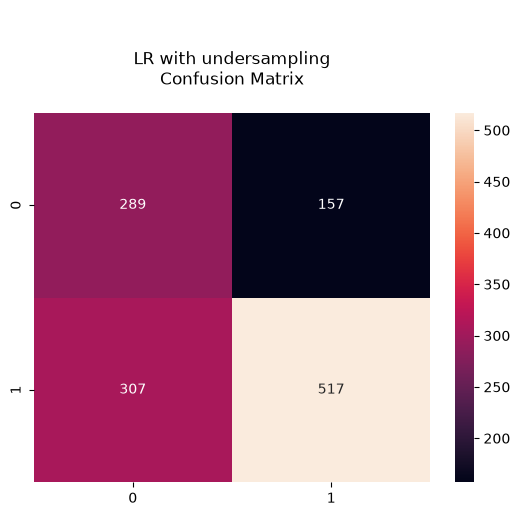

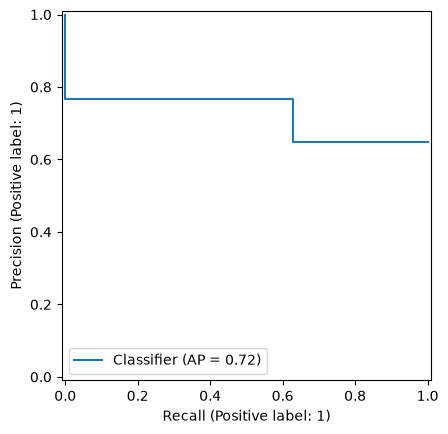

In [34]:
lr_under_pred = lr_under.predict(X_val_std)
print('MSE =', mean_squared_error(lr_under_pred, y_val_t))
print('Accuracy =',accuracy_score(lr_under_pred, y_val_t))
print('Precision =', precision_score(lr_under_pred, y_val_t))
print('Recall =', recall_score(lr_under_pred, y_val_t))
print('F1 Score =', f1_score(lr_under_pred, y_val_t))

print(classification_report(y_val_t, lr_under_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, lr_under_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nLR with undersampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, lr_under_pred)

MSE = 0.36299212598425196
Accuracy = 0.637007874015748
Precision = 0.6274271844660194
Recall = 0.7704918032786885
F1 Score = 0.691638795986622
              precision    recall  f1-score   support

unsuccessful       0.49      0.65      0.56       446
  successful       0.77      0.63      0.69       824

    accuracy                           0.64      1270
   macro avg       0.63      0.64      0.63      1270
weighted avg       0.67      0.64      0.65      1270

Out[35]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x116c0cd10>


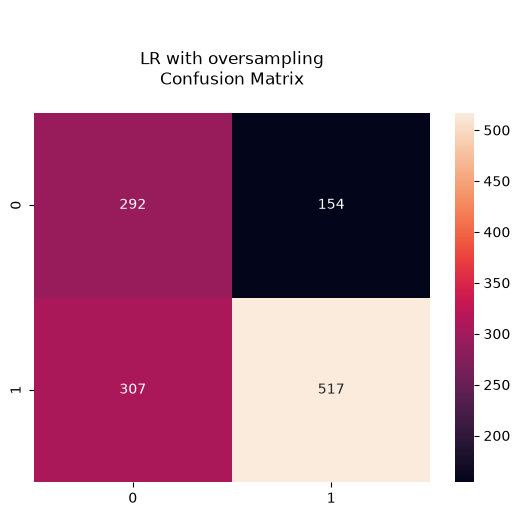

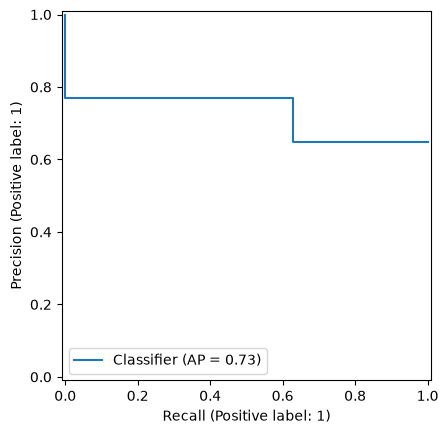

In [35]:
lr_over_pred = lr_over.predict(X_val_std)
print('MSE =', mean_squared_error(lr_over_pred, y_val_t))
print('Accuracy =',accuracy_score(lr_over_pred, y_val_t))
print('Precision =', precision_score(lr_over_pred, y_val_t))
print('Recall =', recall_score(lr_over_pred, y_val_t))
print('F1 Score =', f1_score(lr_over_pred, y_val_t))

print(classification_report(y_val_t, lr_over_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, lr_over_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nLR with oversampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, lr_over_pred)

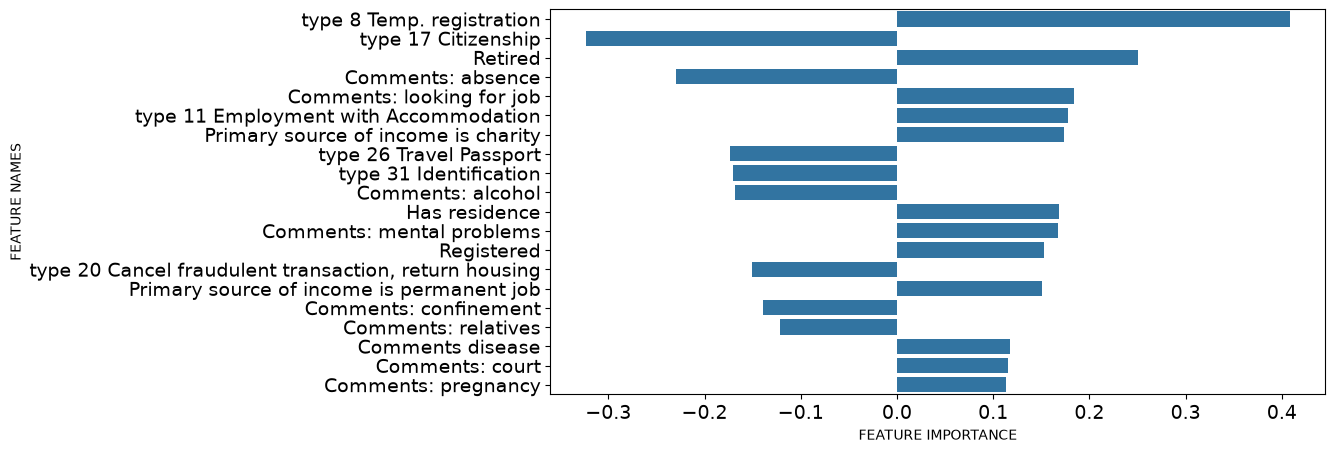

In [36]:
plot_feature_importance(lr_under.coef_[0], x_columns_t, 'Logistic Regression with undersampling ')

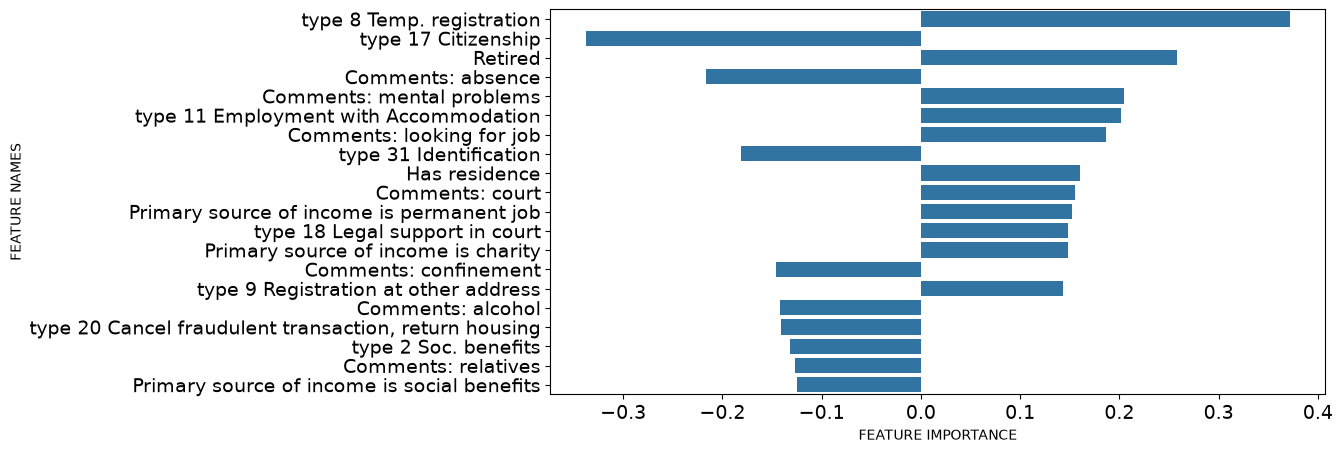

In [37]:
plot_feature_importance(lr_over.coef_[0], x_columns_t, 'Logistic Regression with oversampling ')

## Support Vector Machine

In [38]:
svm_under = SVC(kernel = 'linear', random_state=SEED)
svm_over = SVC(kernel = 'linear', random_state=SEED)

(we first try everything with default parameters, but linear kernel is needed here since otherwise we would not be able to get coeffs for feature importance)

In [39]:
svm_under.fit(X_res_train_std, y_res_train_std)
svm_over.fit(X_ros_train_std, y_ros_train_std)

Out[39]: SVC(kernel='linear', random_state=42)


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


MSE = 0.36220472440944884
Accuracy = 0.6377952755905512
Precision = 0.6310679611650486
Recall = 0.7692307692307693
F1 Score = 0.6933333333333334
              precision    recall  f1-score   support

unsuccessful       0.49      0.65      0.56       446
  successful       0.77      0.63      0.69       824

    accuracy                           0.64      1270
   macro avg       0.63      0.64      0.63      1270
weighted avg       0.67      0.64      0.65      1270

Out[40]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x116e90810>


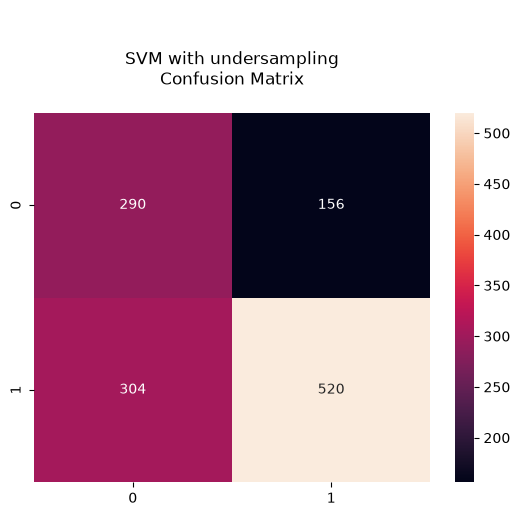

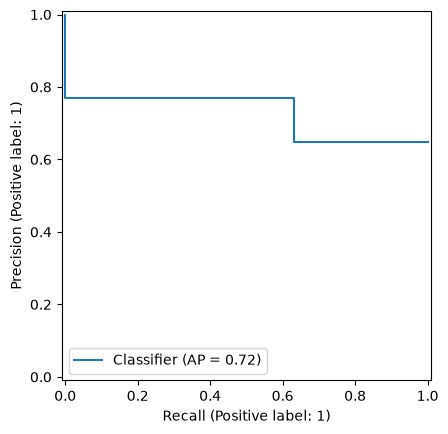

In [40]:
svm_under_pred = svm_under.predict(X_val_std)
print('MSE =', mean_squared_error(svm_under_pred, y_val_t))
print('Accuracy =',accuracy_score(svm_under_pred, y_val_t))
print('Precision =', precision_score(svm_under_pred, y_val_t))
print('Recall =', recall_score(svm_under_pred, y_val_t))
print('F1 Score =', f1_score(svm_under_pred, y_val_t))

print(classification_report(y_val_t, svm_under_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, svm_under_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nSVM with undersampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, svm_under_pred)

MSE = 0.36850393700787404
Accuracy = 0.631496062992126
Precision = 0.5983009708737864
Recall = 0.7825396825396825
F1 Score = 0.6781292984869326
              precision    recall  f1-score   support

unsuccessful       0.48      0.69      0.57       446
  successful       0.78      0.60      0.68       824

    accuracy                           0.63      1270
   macro avg       0.63      0.65      0.62      1270
weighted avg       0.68      0.63      0.64      1270

Out[41]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x117024b10>


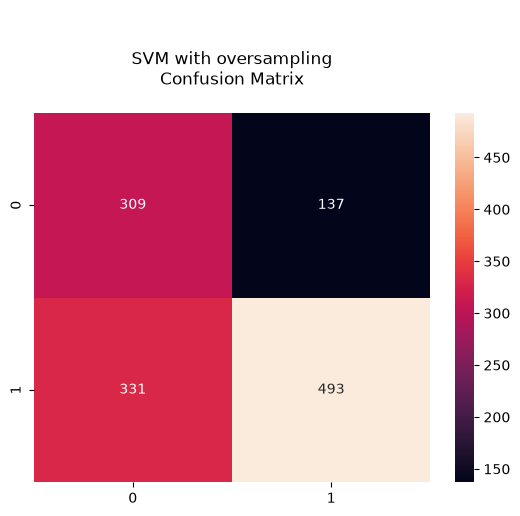

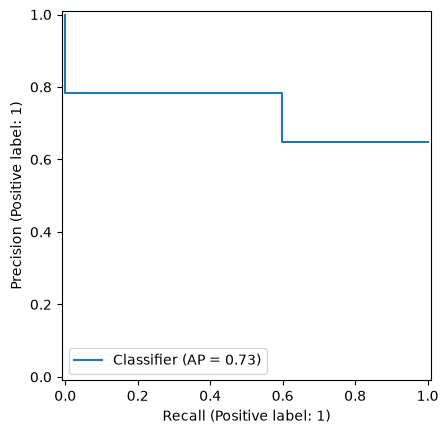

In [41]:
svm_over_pred = svm_over.predict(X_val_std)
print('MSE =', mean_squared_error(svm_over_pred, y_val_t))
print('Accuracy =',accuracy_score(svm_over_pred, y_val_t))
print('Precision =', precision_score(svm_over_pred, y_val_t))
print('Recall =', recall_score(svm_over_pred, y_val_t))
print('F1 Score =', f1_score(svm_over_pred, y_val_t))

print(classification_report(y_val_t, svm_over_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, svm_over_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nSVM with oversampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, svm_over_pred)

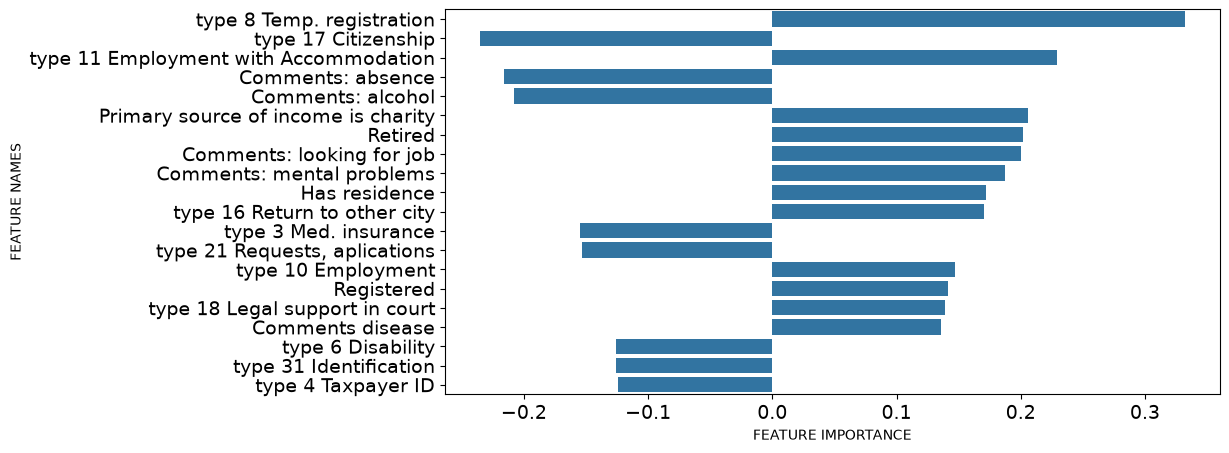

In [42]:
plot_feature_importance(svm_under.coef_[0], x_columns_t, 'Support Vector Machine with undersampling ')

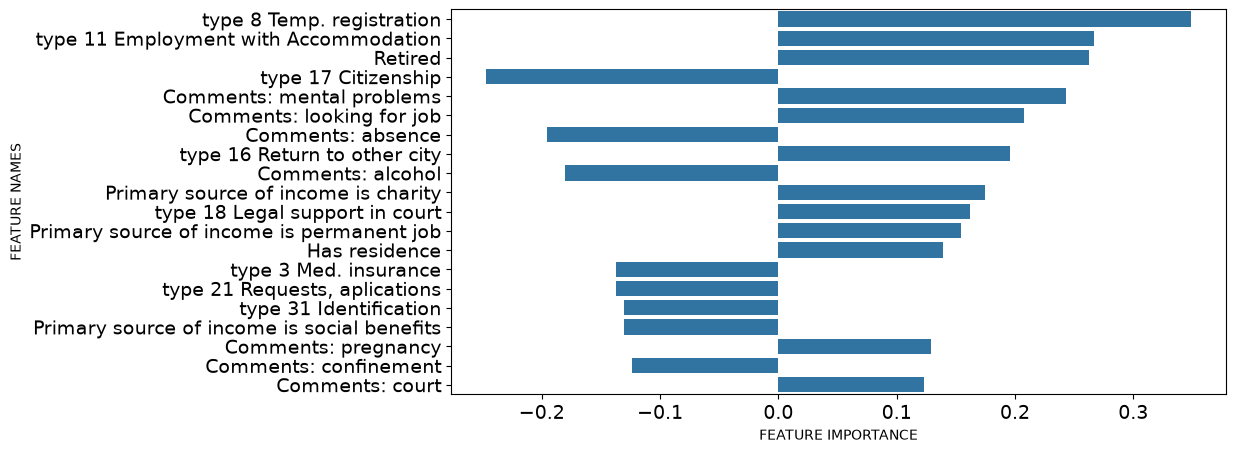

In [43]:
plot_feature_importance(svm_over.coef_[0], x_columns_t, 'Support Vector Machine with oversampling ')

## Decision Tree Classifier

In [44]:
dt_under = DecisionTreeClassifier(random_state=SEED)
dt_over = DecisionTreeClassifier(random_state=SEED)

In [45]:
dt_under.fit(X_res_train_std, y_res_train_std)
dt_over.fit(X_ros_train_std, y_ros_train_std)

Out[45]: DecisionTreeClassifier(random_state=42)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

MSE = 0.27716535433070866
Accuracy = 0.7228346456692913
Precision = 0.720873786407767
Recall = 0.8296089385474861
F1 Score = 0.7714285714285715
              precision    recall  f1-score   support

unsuccessful       0.58      0.73      0.65       446
  successful       0.83      0.72      0.77       824

    accuracy                           0.72      1270
   macro avg       0.71      0.72      0.71      1270
weighted avg       0.74      0.72      0.73      1270

Out[46]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x1172fe150>


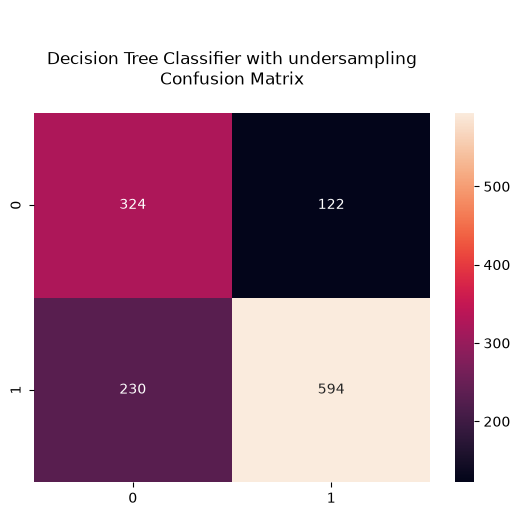

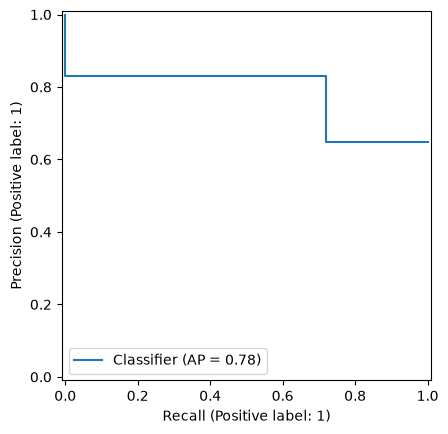

In [46]:
dt_under_pred = dt_under.predict(X_val_std)
print('MSE =', mean_squared_error(dt_under_pred, y_val_t))
print('Accuracy =',accuracy_score(dt_under_pred, y_val_t))
print('Precision =', precision_score(dt_under_pred, y_val_t))
print('Recall =', recall_score(dt_under_pred, y_val_t))
print('F1 Score =', f1_score(dt_under_pred, y_val_t))

print(classification_report(y_val_t, dt_under_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, dt_under_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nDecision Tree Classifier with undersampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, dt_under_pred)

MSE = 0.23070866141732282
Accuracy = 0.7692913385826772
Precision = 0.7912621359223301
Recall = 0.8434670116429496
F1 Score = 0.8165309956167814
              precision    recall  f1-score   support

unsuccessful       0.65      0.73      0.69       446
  successful       0.84      0.79      0.82       824

    accuracy                           0.77      1270
   macro avg       0.75      0.76      0.75      1270
weighted avg       0.78      0.77      0.77      1270

Out[47]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x1173a7a50>


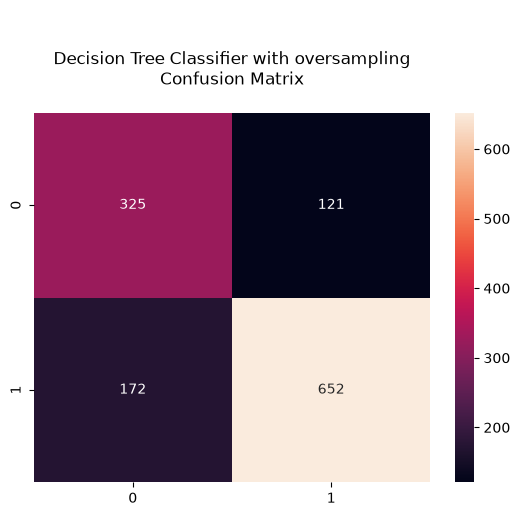

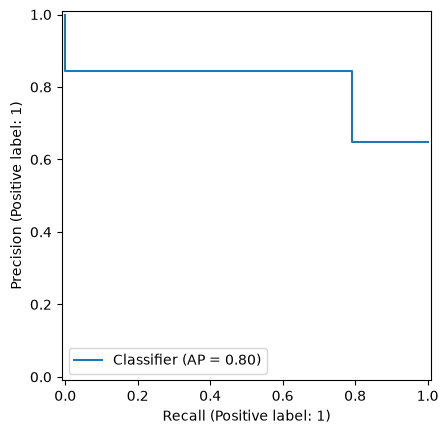

In [47]:
dt_over_pred = dt_over.predict(X_val_std)
print('MSE =', mean_squared_error(dt_over_pred, y_val_t))
print('Accuracy =',accuracy_score(dt_over_pred, y_val_t))
print('Precision =', precision_score(dt_over_pred, y_val_t))
print('Recall =', recall_score(dt_over_pred, y_val_t))
print('F1 Score =', f1_score(dt_over_pred, y_val_t))

print(classification_report(y_val_t, dt_over_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, dt_over_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nDecision Tree Classifier with oversampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, dt_over_pred)

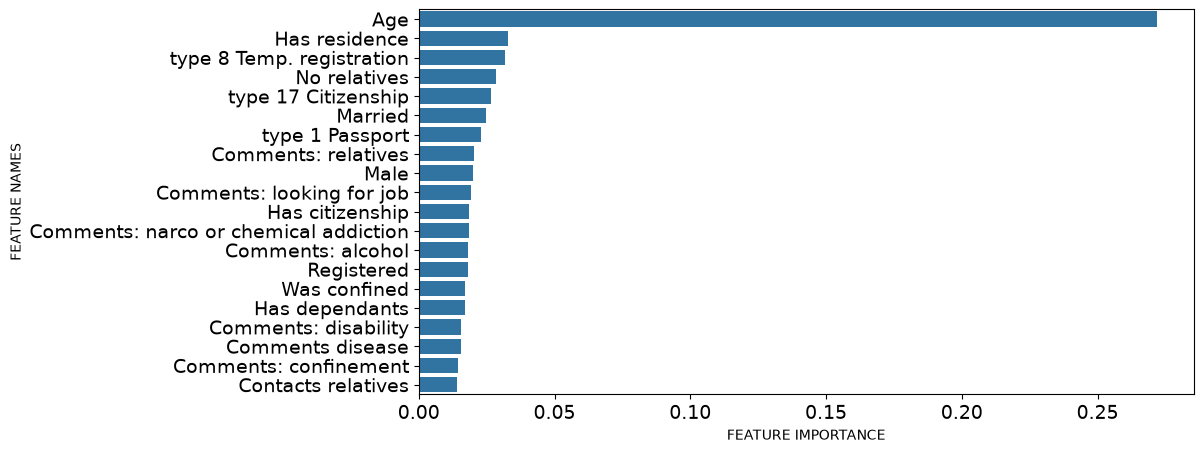

In [48]:
plot_feature_importance(dt_under.feature_importances_, x_columns_t, 'Decision Tree Classifier with undersampling ')

In [49]:
get_signs(dt_over, x_columns_t)

Out[49]: 
array([ 1., -1.,  1., -1.,  1., -1.,  1.,  1., -1.,  1.,  1., -1., -1.,
        1., -1.,  1.,  1.,  1.,  1.,  1.,  1., -1.,  1., -1.,  1.,  1.,
        1.,  1., -1.,  1.,  1., -1.,  1.,  1., -1.,  1., -1., -1.,  1.,
       -1.,  1., -1.,  1.,  1.,  1.,  1., -1.,  1., nan,  1., -1., -1.,
        1.,  1., -1., -1., -1., -1., -1.,  1.,  1.,  1.,  1.,  1., -1.,
       -1.,  1., -1.,  1., -1.,  1., -1., -1., -1.,  1., -1., -1.,  1.,
        1.,  1., -1.,  1.,  1., -1., -1.,  1., -1.,  1.,  1.,  1.,  1.,
       -1.,  1., nan, -1.,  1.])


array([ 1., -1.,  1., -1.,  1., -1.,  1.,  1., -1.,  1.,  1., -1., -1.,
        1., -1.,  1.,  1.,  1.,  1.,  1.,  1., -1.,  1., -1.,  1.,  1.,
        1.,  1., -1.,  1.,  1., -1.,  1.,  1., -1.,  1., -1., -1.,  1.,
       -1.,  1., -1.,  1.,  1.,  1.,  1., -1.,  1., nan,  1., -1., -1.,
        1.,  1., -1., -1., -1., -1., -1.,  1.,  1.,  1.,  1.,  1., -1.,
       -1.,  1., -1.,  1., -1.,  1., -1., -1., -1.,  1., -1., -1.,  1.,
        1.,  1., -1.,  1.,  1., -1., -1.,  1., -1.,  1.,  1.,  1.,  1.,
       -1.,  1., nan, -1.,  1.])

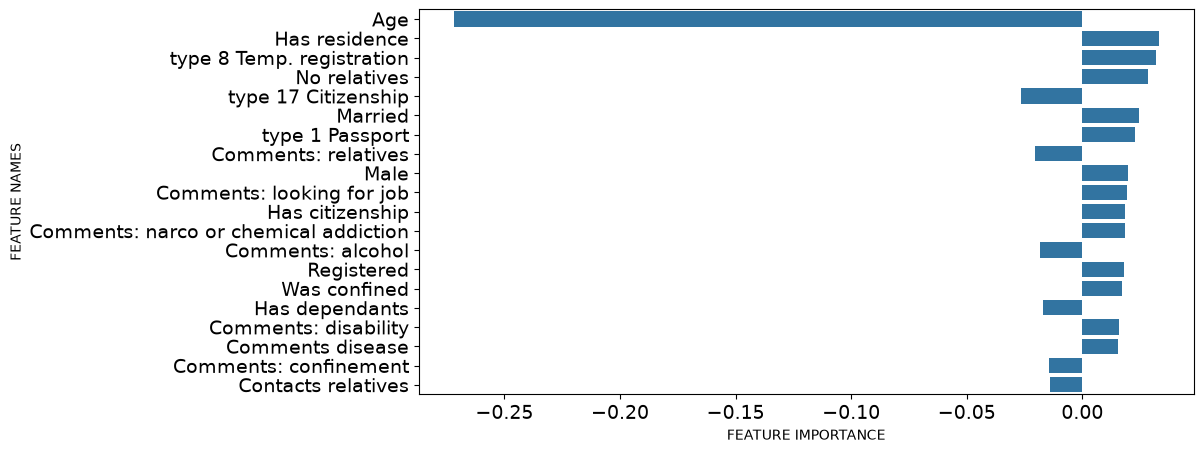

In [50]:
plot_icicle(dt_under, x_columns_t, dt_under.feature_importances_)

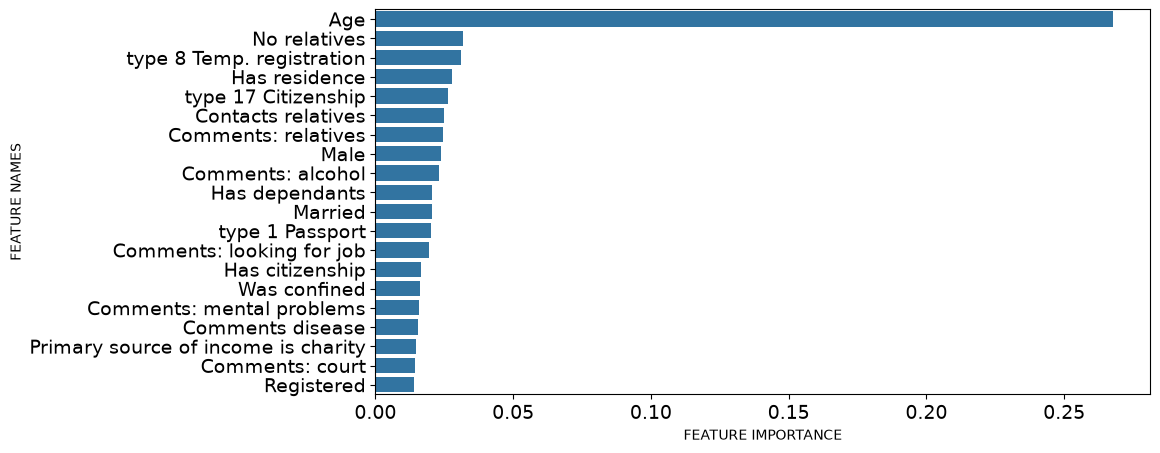

In [51]:
plot_feature_importance(dt_over.feature_importances_, x_columns_t, 'Decision Tree Classifier with oversampling ')

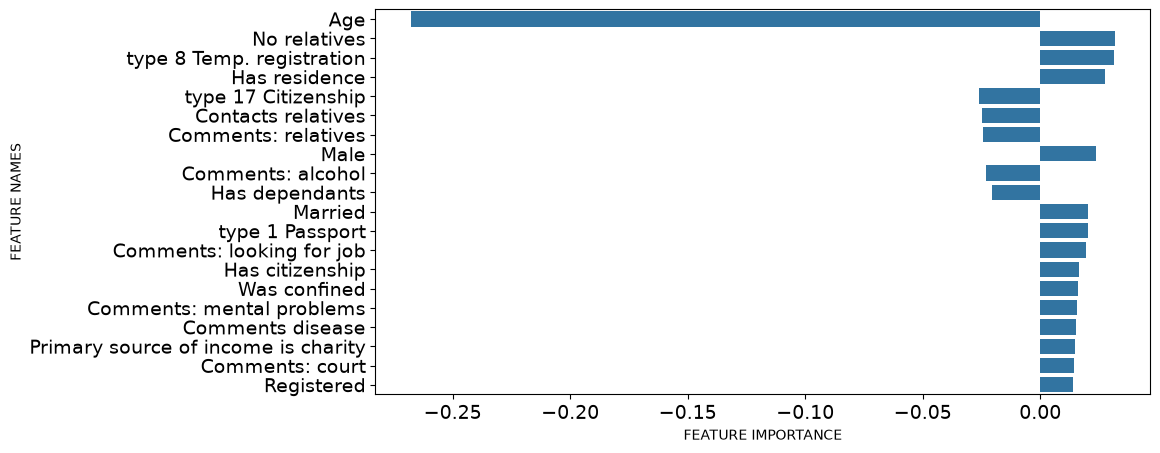

In [52]:
plot_icicle(dt_over, x_columns_t, dt_over.feature_importances_)

## k Nearest Neighbors

In [53]:
knn_under = KNeighborsClassifier()
knn_over = KNeighborsClassifier()

In [54]:
knn_under.fit(X_res_train_std, y_res_train_std)
knn_over.fit(X_ros_train_std, y_ros_train_std)

Out[54]: KNeighborsClassifier()


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


MSE = 0.3653543307086614
Accuracy = 0.6346456692913386
Precision = 0.6116504854368932
Recall = 0.7777777777777778
F1 Score = 0.6847826086956522
              precision    recall  f1-score   support

unsuccessful       0.49      0.68      0.57       446
  successful       0.78      0.61      0.68       824

    accuracy                           0.63      1270
   macro avg       0.63      0.64      0.63      1270
weighted avg       0.68      0.63      0.64      1270

Out[55]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x116fce610>


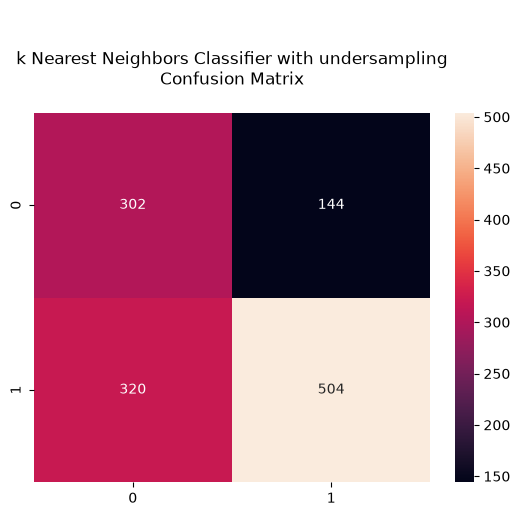

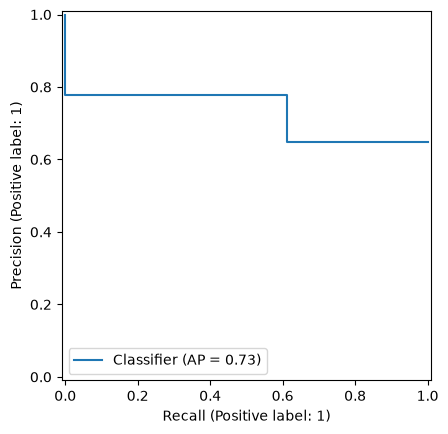

In [55]:
knn_under_pred = knn_under.predict(X_val_std)
print('MSE =', mean_squared_error(knn_under_pred, y_val_t))
print('Accuracy =',accuracy_score(knn_under_pred, y_val_t))
print('Precision =', precision_score(knn_under_pred, y_val_t))
print('Recall =', recall_score(knn_under_pred, y_val_t))
print('F1 Score =', f1_score(knn_under_pred, y_val_t))

print(classification_report(y_val_t, knn_under_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, knn_under_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nk Nearest Neighbors Classifier with undersampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, knn_under_pred)

MSE = 0.3551181102362205
Accuracy = 0.6448818897637796
Precision = 0.6395631067961165
Recall = 0.7738619676945668
F1 Score = 0.7003322259136212
              precision    recall  f1-score   support

unsuccessful       0.50      0.65      0.56       446
  successful       0.77      0.64      0.70       824

    accuracy                           0.64      1270
   macro avg       0.63      0.65      0.63      1270
weighted avg       0.68      0.64      0.65      1270

Out[56]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x117510f90>


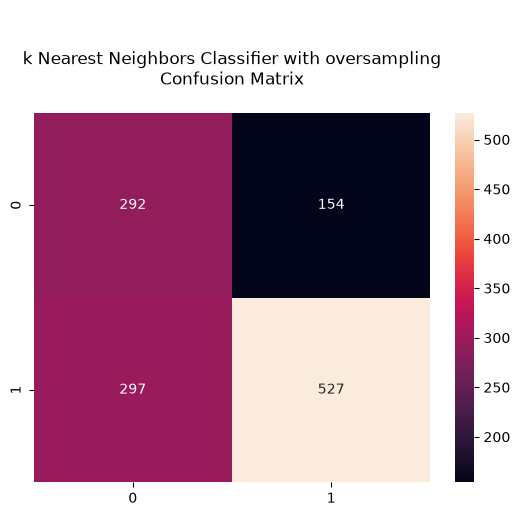

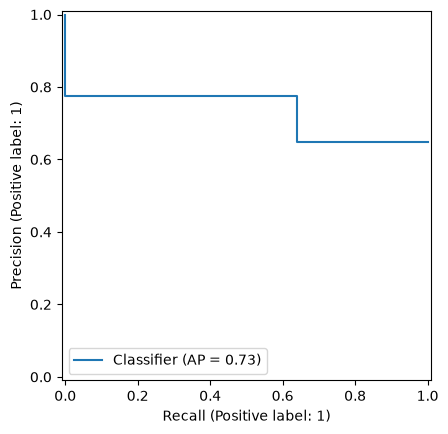

In [56]:
knn_over_pred = knn_over.predict(X_val_std)
print('MSE =', mean_squared_error(knn_over_pred, y_val_t))
print('Accuracy =',accuracy_score(knn_over_pred, y_val_t))
print('Precision =', precision_score(knn_over_pred, y_val_t))
print('Recall =', recall_score(knn_over_pred, y_val_t))
print('F1 Score =', f1_score(knn_over_pred, y_val_t))

print(classification_report(y_val_t, knn_over_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, knn_over_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nk Nearest Neighbors Classifier with oversampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, knn_over_pred)

It apperars that there is no quick and easy way to derive feature importances for kNeighborsClassifier. We will later derive them for all models in unified way, to prevernt variance caused by differences in nature of models.

## Random Forest

In [57]:
rf_under = RandomForestClassifier(random_state=SEED)
rf_over = RandomForestClassifier(random_state=SEED)

In [58]:
rf_under.fit(X_res_train_std, y_res_train_std)
rf_over.fit(X_ros_train_std, y_ros_train_std)

Out[58]: RandomForestClassifier(random_state=42)


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

MSE = 0.22913385826771654
Accuracy = 0.7708661417322835
Precision = 0.75
Recall = 0.8790896159317212
F1 Score = 0.8094302554027505
              precision    recall  f1-score   support

unsuccessful       0.64      0.81      0.71       446
  successful       0.88      0.75      0.81       824

    accuracy                           0.77      1270
   macro avg       0.76      0.78      0.76      1270
weighted avg       0.79      0.77      0.78      1270

Out[59]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x12320e810>


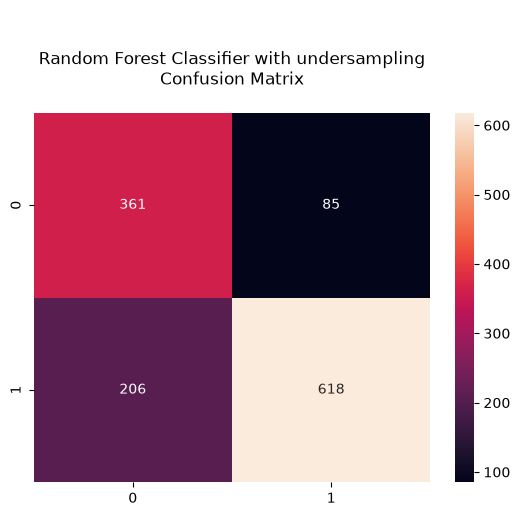

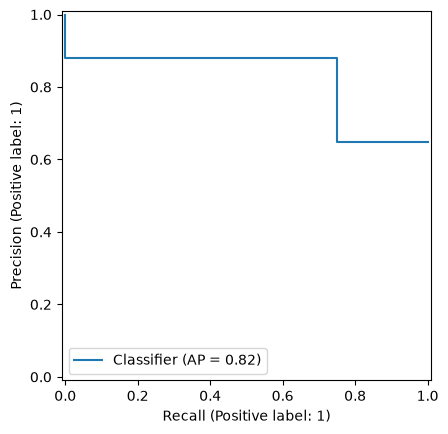

In [59]:
rf_under_pred = rf_under.predict(X_val_std)
print('MSE =', mean_squared_error(rf_under_pred, y_val_t))
print('Accuracy =',accuracy_score(rf_under_pred, y_val_t))
print('Precision =', precision_score(rf_under_pred, y_val_t))
print('Recall =', recall_score(rf_under_pred, y_val_t))
print('F1 Score =', f1_score(rf_under_pred, y_val_t))

print(classification_report(y_val_t, rf_under_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, rf_under_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nRandom Forest Classifier with undersampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, rf_under_pred)

MSE = 0.1858267716535433
Accuracy = 0.8141732283464567
Precision = 0.8592233009708737
Recall = 0.855072463768116
F1 Score = 0.8571428571428571
              precision    recall  f1-score   support

unsuccessful       0.74      0.73      0.73       446
  successful       0.86      0.86      0.86       824

    accuracy                           0.81      1270
   macro avg       0.80      0.80      0.80      1270
weighted avg       0.81      0.81      0.81      1270

Out[60]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x123276d90>


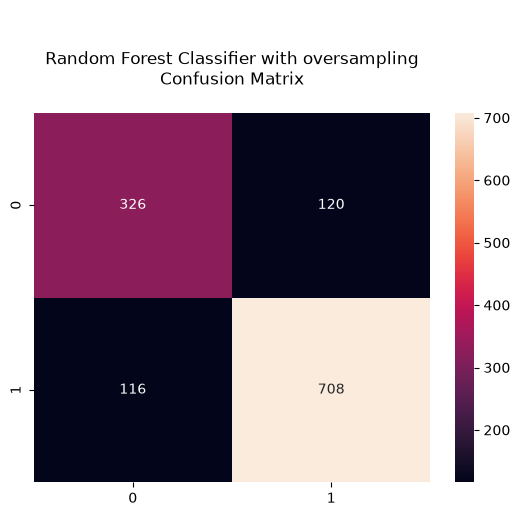

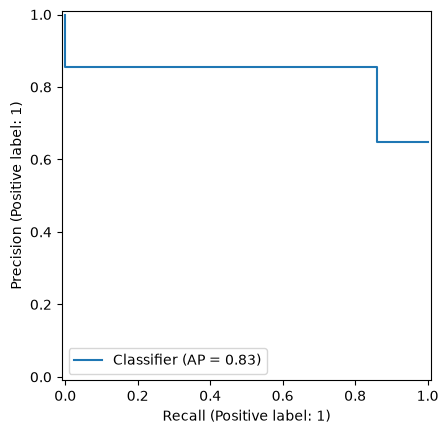

In [60]:
rf_over_pred = rf_over.predict(X_val_std)
print('MSE =', mean_squared_error(rf_over_pred, y_val_t))
print('Accuracy =',accuracy_score(rf_over_pred, y_val_t))
print('Precision =', precision_score(rf_over_pred, y_val_t))
print('Recall =', recall_score(rf_over_pred, y_val_t))
print('F1 Score =', f1_score(rf_over_pred, y_val_t))

print(classification_report(y_val_t, rf_over_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, rf_over_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nRandom Forest Classifier with oversampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, rf_over_pred)

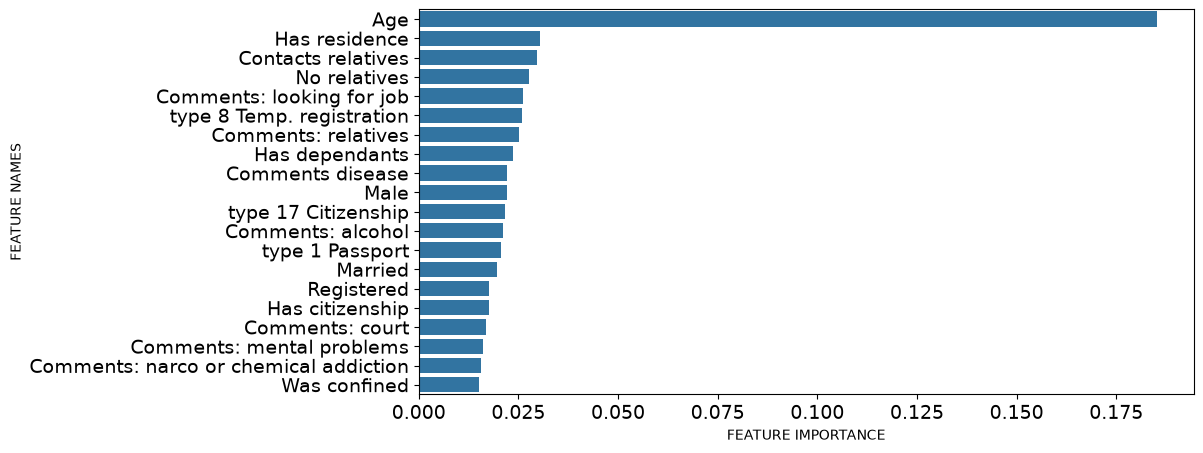

In [61]:
plot_feature_importance(rf_under.feature_importances_, x_columns_t, 'Random Forest Classifier with undersampling ')

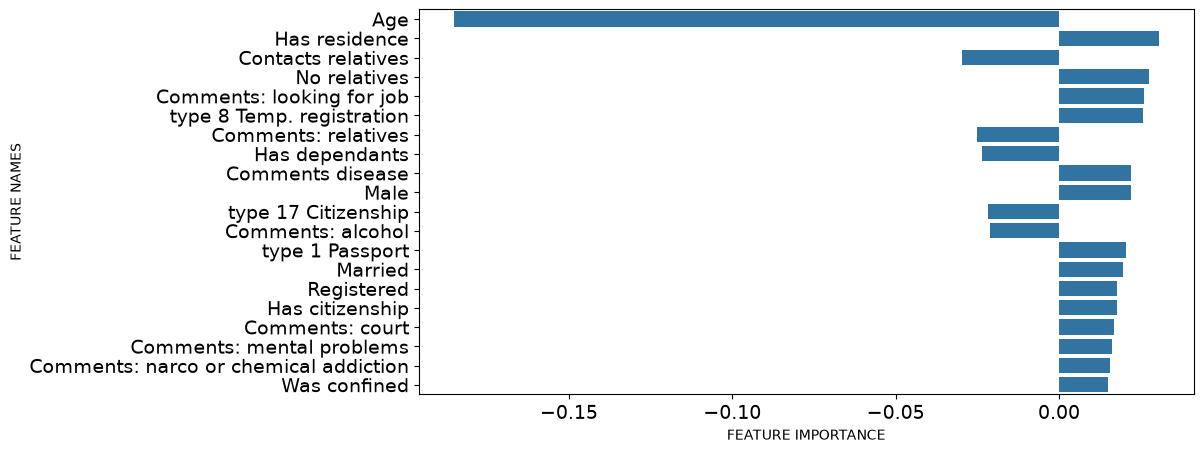

In [62]:
plot_icicle(rf_under, x_columns_t, rf_under.feature_importances_)

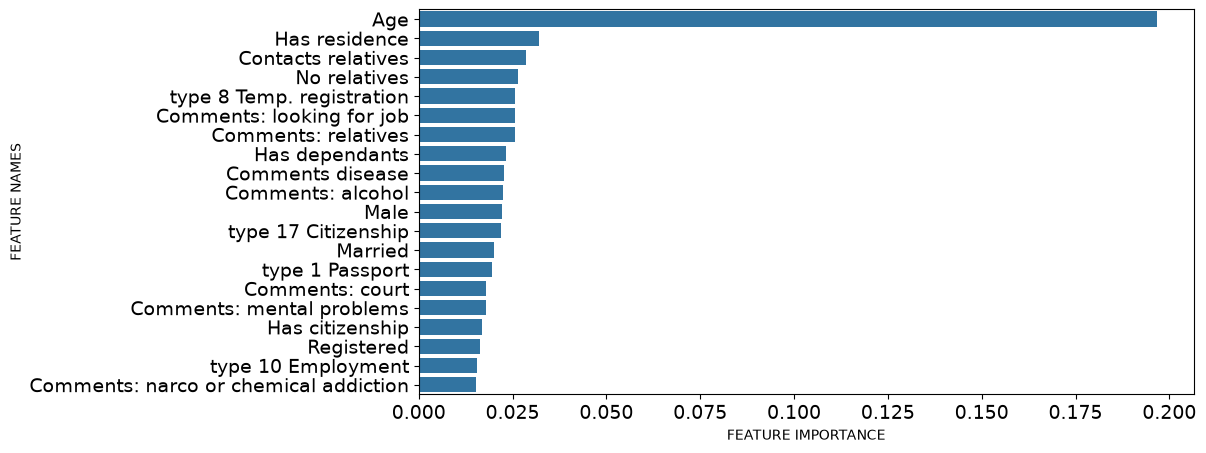

In [63]:
plot_feature_importance(rf_over.feature_importances_, x_columns_t, 'Random Forest Classifier with oversampling ')

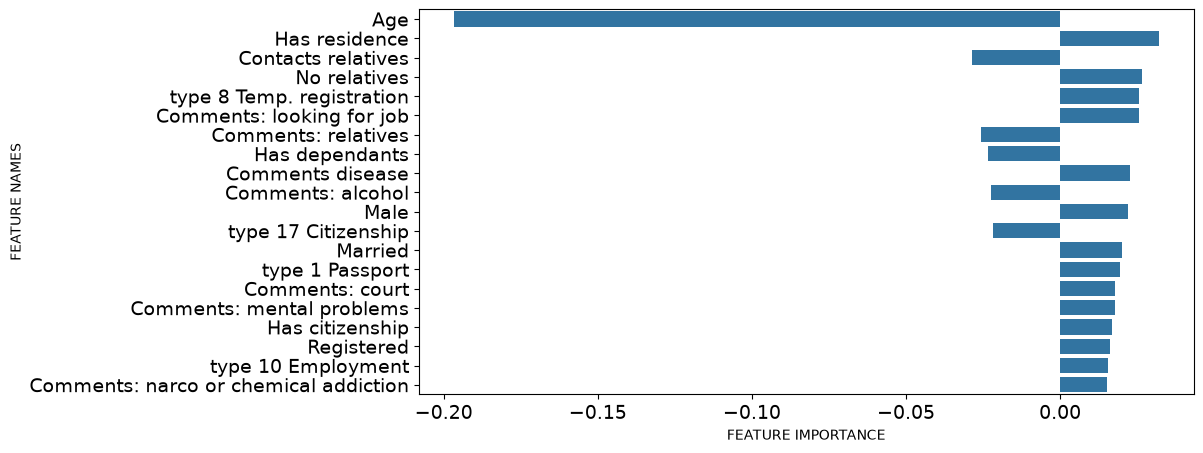

In [64]:
plot_icicle(rf_over, x_columns_t, rf_over.feature_importances_)

## Fully Connected Neural Network

In [65]:
EPOCHS = 50
BATCH_SIZE = 64
LEARNING_RATE = 0.001

In [66]:
## train data
class TrainData(Dataset):
    
    def __init__(self, X_data, y_data):
        self.X_data = X_data
        self.y_data = y_data
        
    def __getitem__(self, index):
        return self.X_data[index], self.y_data[index]
        
    def __len__ (self):
        return len(self.X_data)


train_data_under = TrainData(torch.FloatTensor(np.asarray(X_res_train_std)), 
                             torch.FloatTensor(np.asarray(y_res_train_std)))
train_data_over = TrainData(torch.FloatTensor(np.asarray(X_ros_train_std)), 
                            torch.FloatTensor(np.asarray(y_ros_train_std)))

In [67]:
## test data    
class TestData(Dataset):
    
    def __init__(self, X_data):
        self.X_data = X_data
        
    def __getitem__(self, index):
        return self.X_data[index]
        
    def __len__ (self):
        return len(self.X_data)
    

val_data = TestData(torch.FloatTensor(X_val_std))

In [68]:
train_loader_under = DataLoader(dataset=train_data_under, batch_size=BATCH_SIZE, shuffle=True)
train_loader_over = DataLoader(dataset=train_data_over, batch_size=BATCH_SIZE, shuffle=True)

In [69]:
test_loader = DataLoader(dataset=val_data, batch_size=1)

In [70]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [71]:
def binary_acc(y_pred, y_test):
    y_pred_tag = torch.round(torch.sigmoid(y_pred))

    correct_results_sum = (y_pred_tag == y_test).sum().float()
    acc = correct_results_sum/y_test.shape[0]
    acc = torch.round(acc * 100)
    
    return acc

In [72]:
size_1 = 1024
size_2 = 512
size_3 = 256
dropout_rate = 0.2

In [73]:
class BinaryClassification(nn.Module):
    def __init__(self, input_size):
        super(BinaryClassification, self).__init__()
        # Number of input features
        self.layer_1 = nn.Linear(input_size, size_1) 
        self.layer_2 = nn.Linear(size_1, size_2)
        self.layer_3 = nn.Linear(size_2, size_3)
        self.layer_out = nn.Linear(size_3, 1) 
        
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=dropout_rate)
        self.batchnorm1 = nn.BatchNorm1d(size_1)
        self.batchnorm2 = nn.BatchNorm1d(size_2)
        self.batchnorm3 = nn.BatchNorm1d(size_3)
        
    def forward(self, inputs):
        x = self.relu(self.layer_1(inputs))
        x = self.batchnorm1(x)
        x = self.dropout(x)
        x = self.relu(self.layer_2(x))
        x = self.batchnorm2(x)
        x = self.dropout(x)
        x = self.relu(self.layer_3(x))
        x = self.batchnorm3(x)
        x = self.dropout(x)
        x = self.layer_out(x)
        
        return x

In [74]:
model = BinaryClassification(X_train_std.shape[1])
model.to(device)
print(model)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

BinaryClassification(
  (layer_1): Linear(in_features=96, out_features=1024, bias=True)
  (layer_2): Linear(in_features=1024, out_features=512, bias=True)
  (layer_3): Linear(in_features=512, out_features=256, bias=True)
  (layer_out): Linear(in_features=256, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
  (batchnorm1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batchnorm2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batchnorm3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
)


In [75]:
model.train()
for e in range(1, EPOCHS+1):
    epoch_loss = 0
    epoch_acc = 0
    for X_batch, y_batch in train_loader_under:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        
        y_pred = model(X_batch)
        
        loss = criterion(y_pred, y_batch.unsqueeze(1))
        acc = binary_acc(y_pred, y_batch.unsqueeze(1))
        
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        epoch_acc += acc.item()
        

    print(f'Epoch {e+0:03}: | Loss: {epoch_loss/len(train_loader_under):.5f} | Acc: {epoch_acc/len(train_loader_under):.3f}')

Epoch 001: | Loss: 0.66256 | Acc: 63.125
Epoch 002: | Loss: 0.56458 | Acc: 69.893
Epoch 003: | Loss: 0.52139 | Acc: 74.446
Epoch 004: | Loss: 0.48866 | Acc: 76.429
Epoch 005: | Loss: 0.44880 | Acc: 78.482
Epoch 006: | Loss: 0.41611 | Acc: 80.446
Epoch 007: | Loss: 0.39529 | Acc: 81.571
Epoch 008: | Loss: 0.38078 | Acc: 83.107
Epoch 009: | Loss: 0.34823 | Acc: 84.446
Epoch 010: | Loss: 0.32295 | Acc: 85.554
Epoch 011: | Loss: 0.30736 | Acc: 86.179
Epoch 012: | Loss: 0.29209 | Acc: 86.375
Epoch 013: | Loss: 0.28118 | Acc: 87.554
Epoch 014: | Loss: 0.25910 | Acc: 88.982
Epoch 015: | Loss: 0.25302 | Acc: 88.518
Epoch 016: | Loss: 0.25436 | Acc: 89.071
Epoch 017: | Loss: 0.24665 | Acc: 88.643
Epoch 018: | Loss: 0.24221 | Acc: 89.018
Epoch 019: | Loss: 0.24233 | Acc: 88.625
Epoch 020: | Loss: 0.23308 | Acc: 89.571
Epoch 021: | Loss: 0.22958 | Acc: 89.750
Epoch 022: | Loss: 0.20579 | Acc: 90.732
Epoch 023: | Loss: 0.20854 | Acc: 90.696
Epoch 024: | Loss: 0.19828 | Acc: 91.232
Epoch 025: | Los

In [76]:
y_pred_list = []
model.eval()
with torch.no_grad():
    for X_batch in test_loader:
        X_batch = X_batch.to(device)
        y_test_pred = model(X_batch)
        y_test_pred = torch.sigmoid(y_test_pred)
        y_pred_tag = torch.round(y_test_pred)
        y_pred_list.append(y_pred_tag.cpu().numpy())

y_pred_list = [a.squeeze().tolist() for a in y_pred_list]

In [77]:
print(classification_report(y_val_t, y_pred_list, target_names=['unsuccessful', 'successful']))

              precision    recall  f1-score   support

unsuccessful       0.54      0.71      0.61       446
  successful       0.81      0.67      0.74       824

    accuracy                           0.69      1270
   macro avg       0.68      0.69      0.67      1270
weighted avg       0.72      0.69      0.69      1270



Out[78]: Text(0.5, 1.0, '\n\nFCNN with undersampling\nConfusion Matrix\n')


Text(0.5, 1.0, '\n\nFCNN with undersampling\nConfusion Matrix\n')

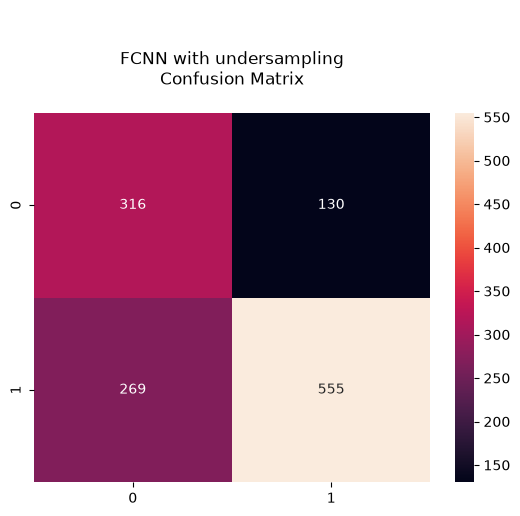

In [78]:
cm = confusion_matrix(y_val_t, y_pred_list)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nFCNN with undersampling\nConfusion Matrix\n')

In [79]:
model_over = BinaryClassification(X_train_std.shape[1])
model_over.to(device)
print(model_over)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_over.parameters(), lr=LEARNING_RATE)

BinaryClassification(
  (layer_1): Linear(in_features=96, out_features=1024, bias=True)
  (layer_2): Linear(in_features=1024, out_features=512, bias=True)
  (layer_3): Linear(in_features=512, out_features=256, bias=True)
  (layer_out): Linear(in_features=256, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
  (batchnorm1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batchnorm2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (batchnorm3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
)


In [80]:
model_over.train()
for e in range(1, EPOCHS+1):
    epoch_loss = 0
    epoch_acc = 0
    for X_batch, y_batch in train_loader_over:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        
        y_pred = model_over(X_batch)
        
        loss = criterion(y_pred, y_batch.unsqueeze(1))
        acc = binary_acc(y_pred, y_batch.unsqueeze(1))
        
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        epoch_acc += acc.item()
        

    print(f'Epoch {e+0:03}: | Loss: {epoch_loss/len(train_loader_over):.5f} | Acc: {epoch_acc/len(train_loader_over):.3f}')

Epoch 001: | Loss: 0.62276 | Acc: 66.864
Epoch 002: | Loss: 0.53503 | Acc: 72.650
Epoch 003: | Loss: 0.47906 | Acc: 76.583
Epoch 004: | Loss: 0.43614 | Acc: 79.951
Epoch 005: | Loss: 0.39693 | Acc: 82.087
Epoch 006: | Loss: 0.36891 | Acc: 83.301
Epoch 007: | Loss: 0.33742 | Acc: 84.777
Epoch 008: | Loss: 0.31731 | Acc: 85.854
Epoch 009: | Loss: 0.30262 | Acc: 86.961
Epoch 010: | Loss: 0.28929 | Acc: 87.019
Epoch 011: | Loss: 0.27482 | Acc: 88.146
Epoch 012: | Loss: 0.26269 | Acc: 88.660
Epoch 013: | Loss: 0.24703 | Acc: 89.612
Epoch 014: | Loss: 0.24338 | Acc: 89.563
Epoch 015: | Loss: 0.22697 | Acc: 90.311
Epoch 016: | Loss: 0.22636 | Acc: 90.194
Epoch 017: | Loss: 0.21281 | Acc: 90.806
Epoch 018: | Loss: 0.20287 | Acc: 91.107
Epoch 019: | Loss: 0.20253 | Acc: 91.476
Epoch 020: | Loss: 0.19501 | Acc: 91.553
Epoch 021: | Loss: 0.18721 | Acc: 91.835
Epoch 022: | Loss: 0.18931 | Acc: 91.592
Epoch 023: | Loss: 0.18826 | Acc: 91.864
Epoch 024: | Loss: 0.17583 | Acc: 92.621
Epoch 025: | Los

In [81]:
y_pred_list_over = []
model_over.eval()
with torch.no_grad():
    for X_batch in test_loader:
        X_batch = X_batch.to(device)
        y_test_pred = model_over(X_batch)
        y_test_pred = torch.sigmoid(y_test_pred)
        y_pred_tag = torch.round(y_test_pred)
        y_pred_list_over.append(y_pred_tag.cpu().numpy())

y_pred_list_over = [a.squeeze().tolist() for a in y_pred_list_over]

In [82]:
print(classification_report(y_val_t, y_pred_list_over, target_names=['unsuccessful', 'successful']))

              precision    recall  f1-score   support

unsuccessful       0.64      0.65      0.65       446
  successful       0.81      0.80      0.81       824

    accuracy                           0.75      1270
   macro avg       0.73      0.73      0.73      1270
weighted avg       0.75      0.75      0.75      1270



Out[83]: Text(0.5, 1.0, '\n\nFCNN with oversampling\nConfusion Matrix\n')


Text(0.5, 1.0, '\n\nFCNN with oversampling\nConfusion Matrix\n')

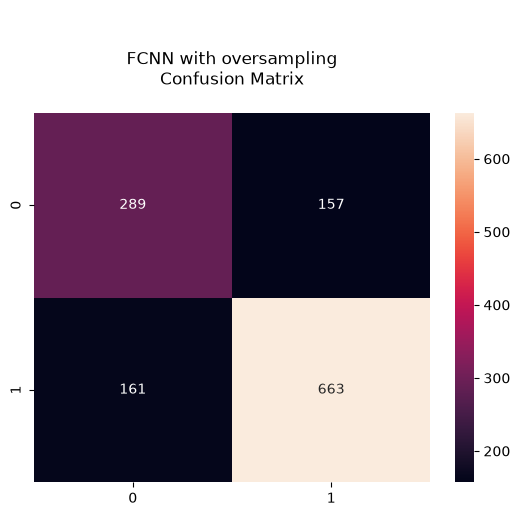

In [83]:
cm = confusion_matrix(y_val_t, y_pred_list_over)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nFCNN with oversampling\nConfusion Matrix\n')

## XGBoost

### From file

There is a problem with loading saved model: the feature names get shuffled (had to ask at stackoverflow to find that out).

Therefore, extracting feature names from loaded model, and shuffling them back in the validation set is needed.

Works fine with joblib, and for some (still unknown) reason does not work with native load_model method, so we leave only joblib here.

In [84]:
xgb = joblib.load('xgb_rm_CORRECTED.model')
xgb_ros = joblib.load('xgb_ros_CORRECTED.model')

In [85]:
features_under = xgb.get_booster().feature_names or list(X_val_t.columns)
features_over = xgb_ros.get_booster().feature_names or list(X_val_t.columns)

In [86]:
print(len(features_over))

96


In [87]:
X_val_t_under = X_val_t[features_under]
X_val_t_over = X_val_t[features_over]

MSE = 0.2094488188976378
Accuracy = 0.7905511811023622
Precision = 0.7706310679611651
Recall = 0.8918539325842697
F1 Score = 0.8268229166666666
              precision    recall  f1-score   support

unsuccessful       0.66      0.83      0.74       446
  successful       0.89      0.77      0.83       824

    accuracy                           0.79      1270
   macro avg       0.78      0.80      0.78      1270
weighted avg       0.81      0.79      0.79      1270

Out[88]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x1412a0ad0>


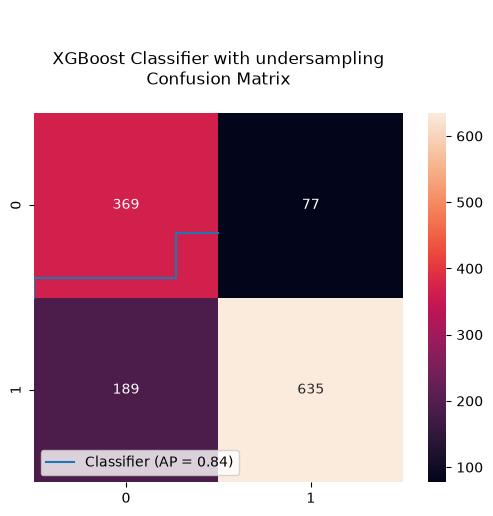

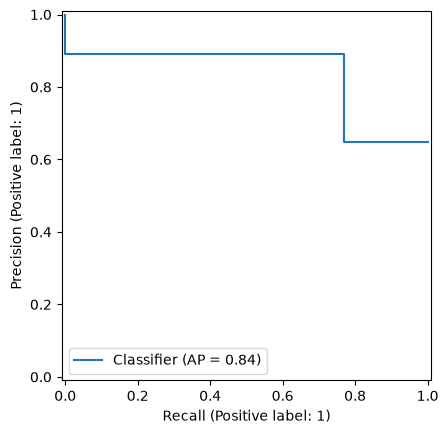

In [88]:
xgb_pred = xgb.predict(X_val_t_under)
print('MSE =', mean_squared_error(xgb_pred, y_val_t))
print('Accuracy =',accuracy_score(xgb_pred, y_val_t))
print('Precision =', precision_score(xgb_pred, y_val_t))
print('Recall =', recall_score(xgb_pred, y_val_t))
print('F1 Score =', f1_score(xgb_pred, y_val_t))
PrecisionRecallDisplay.from_predictions(y_val_t, xgb_pred)

print(classification_report(y_val_t, xgb_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, xgb_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nXGBoost Classifier with undersampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, xgb_pred)

MSE = 0.15905511811023623
Accuracy = 0.8409448818897638
Precision = 0.8701456310679612
Recall = 0.8830049261083743
F1 Score = 0.8765281173594132
              precision    recall  f1-score   support

unsuccessful       0.77      0.79      0.78       446
  successful       0.88      0.87      0.88       824

    accuracy                           0.84      1270
   macro avg       0.82      0.83      0.83      1270
weighted avg       0.84      0.84      0.84      1270

Out[89]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x141692e10>


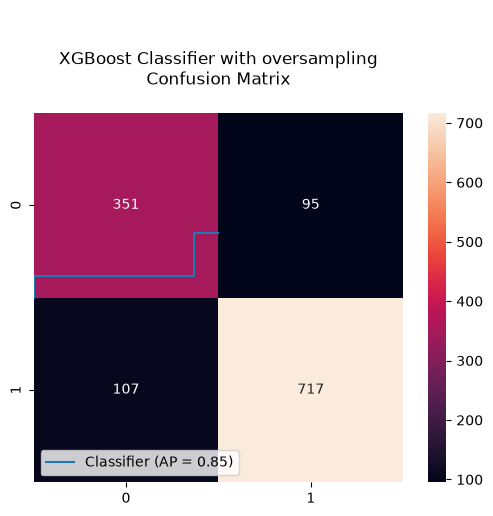

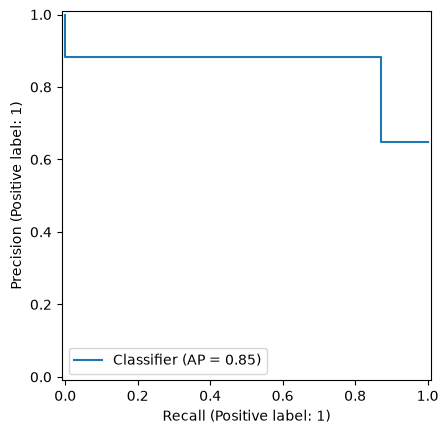

In [89]:
xgb_ros_pred = xgb_ros.predict(X_val_t_over)
print('MSE =', mean_squared_error(xgb_ros_pred, y_val_t))
print('Accuracy =',accuracy_score(xgb_ros_pred, y_val_t))
print('Precision =', precision_score(xgb_ros_pred, y_val_t))
print('Recall =', recall_score(xgb_ros_pred, y_val_t))
print('F1 Score =', f1_score(xgb_ros_pred, y_val_t))
PrecisionRecallDisplay.from_predictions(y_val_t, xgb_ros_pred)

print(classification_report(y_val_t, xgb_ros_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, xgb_ros_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nXGBoost Classifier with oversampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, xgb_ros_pred)

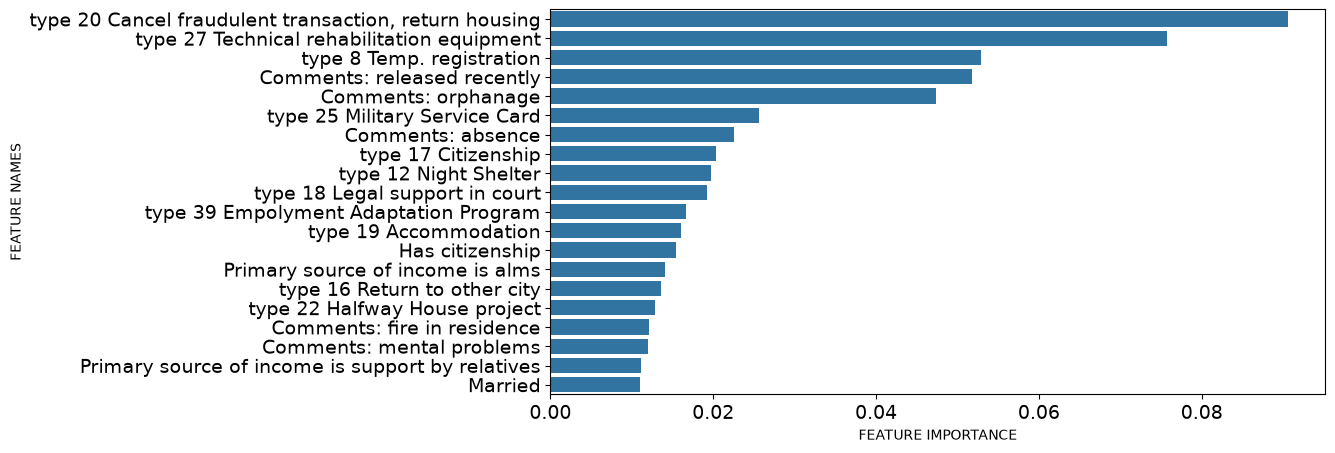

In [90]:
plot_feature_importance(xgb.feature_importances_, features_under, 'XGBoost Classifier with undersampling ')

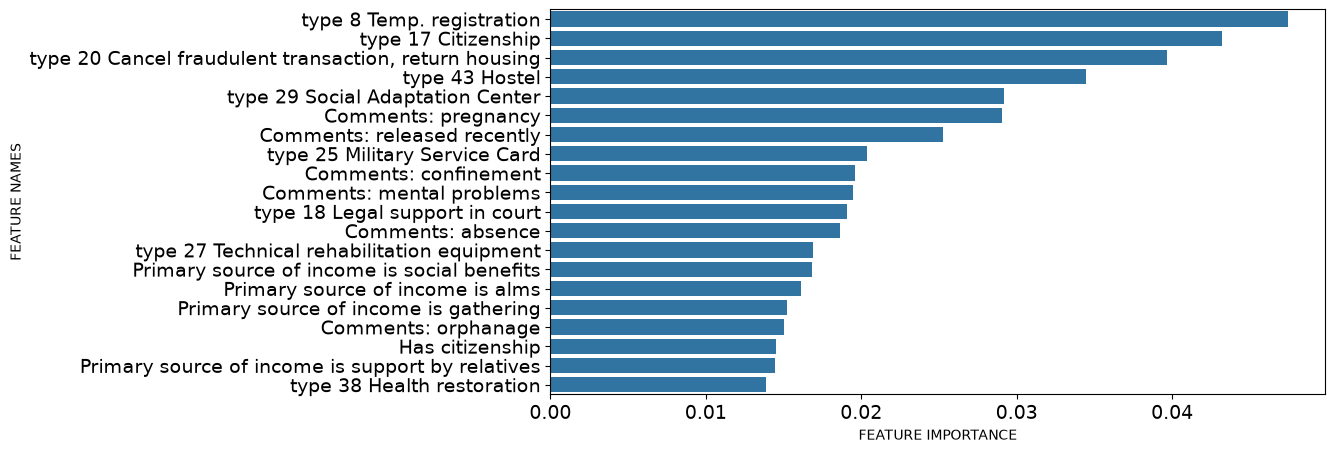

In [91]:
plot_feature_importance(xgb_ros.feature_importances_, features_over, 'XGBoost Classifier with oversampling ')

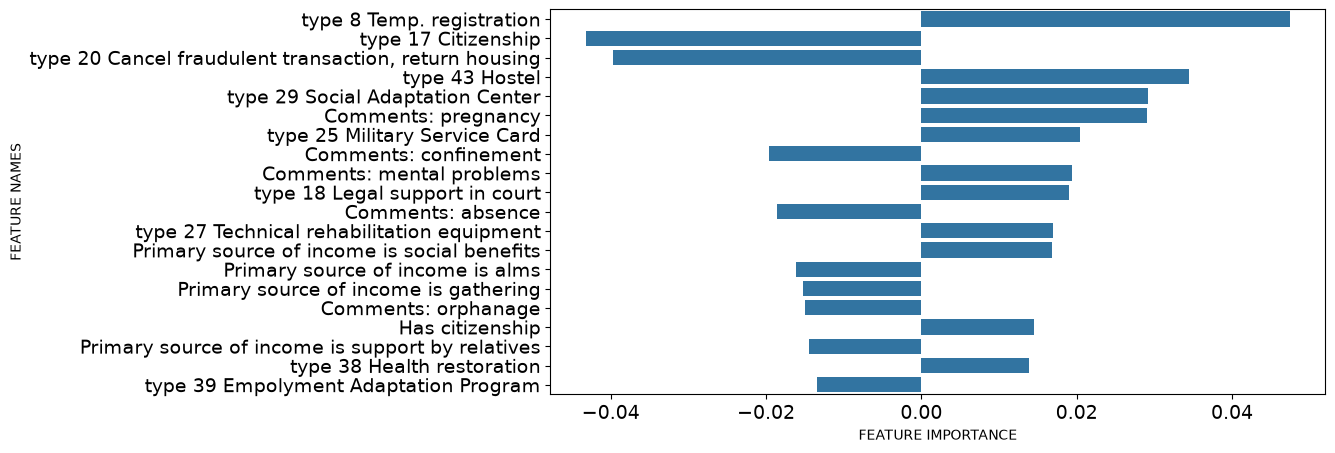

In [92]:
plot_icicle(xgb_ros, features_over, xgb_ros.feature_importances_)

If results from file are fine, skip the next subsection.

### If results from file are not reproducible, re-train model and update file.

In [93]:
def hyperopt_xgb_score(params):
    clf = XGBClassifier(**params)
    # average over 3 folds
    current_score = cross_val_score(clf, X, y, cv=StratifiedKFold(n_splits=3), scoring='accuracy').mean()
    print(current_score, params)
    return -current_score

In [94]:
X = X_res_train_t
y = y_res_train_t
 
 
simple_space_xgb = {
            'n_estimators': hp.choice('n_estimators', range(100, 900)),
            'eta': hp.quniform('eta', 0.01, 0.5, 0.01),
            'max_depth':  hp.choice('max_depth', np.arange(1, 20, dtype=int)),
}
 
best = fmin(fn=hyperopt_xgb_score, space=simple_space_xgb, algo=tpe.suggest, max_evals=20)
print('best:')
print(best)

0.6675979390915323
{'eta': 0.34, 'max_depth': np.int64(1), 'n_estimators': 407}
0.7710191225354733
{'eta': 0.12, 'max_depth': np.int64(6), 'n_estimators': 839}
0.7735380106626334
{'eta': 0.4, 'max_depth': np.int64(14), 'n_estimators': 256}
0.7732574274453263
{'eta': 0.12, 'max_depth': np.int64(19), 'n_estimators': 856}
0.7645704202623017
{'eta': 0.3, 'max_depth': np.int64(9), 'n_estimators': 174}
0.7651297020069592
{'eta': 0.12, 'max_depth': np.int64(10), 'n_estimators': 579}
0.7740975279935355
{'eta': 0.16, 'max_depth': np.int64(13), 'n_estimators': 592}
0.7732586053765492
{'eta': 0.11, 'max_depth': np.int64(10), 'n_estimators': 654}
0.7494363599098176
{'eta': 0.08, 'max_depth': np.int64(6), 'n_estimators': 412}
0.7659688602101902
{'eta': 0.49, 'max_depth': np.int64(16), 'n_estimators': 224}
0.740185830429733
{'eta': 0.23, 'max_depth': np.int64(4), 'n_estimators': 169}
0.7768995907866931
{'eta': 0.37, 'max_depth': np.int64(16), 'n_estimators': 140}
0.7306591938709882
{'eta': 0.5, 'max

In [95]:
ros_best_params = {'eta': 0.34, 'max_depth': 9, 'n_estimators': 853}
#ros_best_params = {'eta': 0.37, 'max_depth': 16, 'n_estimators': 653}
best_params = {'eta': 0.47, 'max_depth': 13, 'n_estimators': 686}
#best_params = {'eta': 0.26, 'max_depth': 11, 'n_estimators': 441}
#best_params = {'eta': 0.21, 'max_depth': 11, 'n_estimators': 825}
#best_params = {'eta': 0.25, 'max_depth': 14, 'n_estimators': 585}# 81 80 81 371 656 1027
#best_params = {'eta': 0.21, 'max_depth': 11, 'n_estimators': 835}# 81 80 81 375 652 1027

In [96]:
xgb = XGBClassifier(**best_params, random_state=SEED, tree_method='exact')
xgb.fit(X_res_train_t, y_res_train_t)

Out[96]: 
XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
              early_stopping_rounds=None, enable_categorical=False, eta=0.47,
              eval_metric=None, gamma=0, gpu_id=-1, grow_policy='depthwise',
              importance_type=None, interaction_constraints='',
              learning_rate=0.469999999, max_bin=256, max_cat_to_onehot=4,
              max_delta_step=0, max_depth=13, max_leaves=0, min_child_weight=1,
              missing=nan, monotone_constraints='()', n_estimators=686,
              n_jobs=0, num_parallel_tree=1, predictor='auto', random_state=42,
              reg_alpha=0, ...)


,base_score,0.5
,booster,'gbtree'
,callbacks,None
,colsample_bylevel,1
,colsample_bynode,1
,colsample_bytree,1
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None
,gamma,0
,gpu_id,-1


In [97]:
xgb_ros = XGBClassifier(**ros_best_params, random_state=SEED, tree_method='exact')
xgb_ros.fit(X_ros_train_t, y_ros_train_t)

Out[97]: 
XGBClassifier(base_score=0.5, booster='gbtree', callbacks=None,
              colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1,
              early_stopping_rounds=None, enable_categorical=False, eta=0.34,
              eval_metric=None, gamma=0, gpu_id=-1, grow_policy='depthwise',
              importance_type=None, interaction_constraints='',
              learning_rate=0.340000004, max_bin=256, max_cat_to_onehot=4,
              max_delta_step=0, max_depth=9, max_leaves=0, min_child_weight=1,
              missing=nan, monotone_constraints='()', n_estimators=853,
              n_jobs=0, num_parallel_tree=1, predictor='auto', random_state=42,
              reg_alpha=0, ...)


,base_score,0.5
,booster,'gbtree'
,callbacks,None
,colsample_bylevel,1
,colsample_bynode,1
,colsample_bytree,1
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None
,gamma,0
,gpu_id,-1


MSE = 0.2062992125984252
Accuracy = 0.7937007874015748
Precision = 0.7766990291262136
Recall = 0.8913649025069638
F1 Score = 0.8300907911802854
Out[98]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x1174c5810>


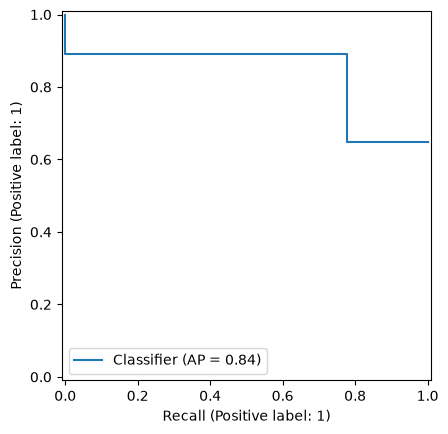

In [98]:
xgb_pred = xgb.predict(X_val_t)
print('MSE =', mean_squared_error(xgb_pred, y_val_t))
print('Accuracy =',accuracy_score(xgb_pred, y_val_t))
print('Precision =', precision_score(xgb_pred, y_val_t))
print('Recall =', recall_score(xgb_pred, y_val_t))
print('F1 Score =', f1_score(xgb_pred, y_val_t))
PrecisionRecallDisplay.from_predictions(y_val_t, xgb_pred)

MSE = 0.16614173228346457
Accuracy = 0.8338582677165355
Precision = 0.866504854368932
Recall = 0.8760736196319019
F1 Score = 0.8712629652226968
Out[99]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x1173f08d0>


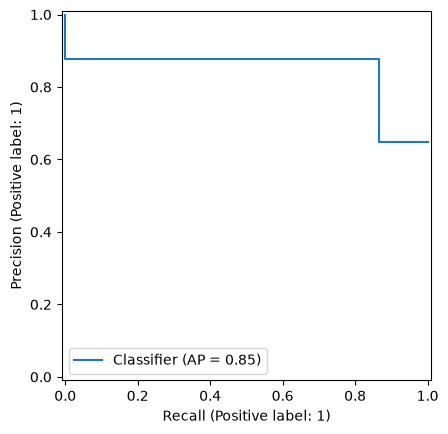

In [99]:
xgb_ros_pred = xgb_ros.predict(X_val_t)
print('MSE =', mean_squared_error(xgb_ros_pred, y_val_t))
print('Accuracy =',accuracy_score(xgb_ros_pred, y_val_t))
print('Precision =', precision_score(xgb_ros_pred, y_val_t))
print('Recall =', recall_score(xgb_ros_pred, y_val_t))
print('F1 Score =', f1_score(xgb_ros_pred, y_val_t))
PrecisionRecallDisplay.from_predictions(y_val_t, xgb_ros_pred)

In [100]:
print(classification_report(y_val_t, xgb_pred, target_names=['unsuccessful', 'successful']))

              precision    recall  f1-score   support

unsuccessful       0.67      0.83      0.74       446
  successful       0.89      0.78      0.83       824

    accuracy                           0.79      1270
   macro avg       0.78      0.80      0.78      1270
weighted avg       0.81      0.79      0.80      1270



In [101]:
print(classification_report(y_val_t, xgb_ros_pred, target_names=['unsuccessful', 'successful']))

              precision    recall  f1-score   support

unsuccessful       0.76      0.77      0.77       446
  successful       0.88      0.87      0.87       824

    accuracy                           0.83      1270
   macro avg       0.82      0.82      0.82      1270
weighted avg       0.83      0.83      0.83      1270



Out[102]: Text(0.5, 1.0, '\n\nXGBoost with undersampling\nМатрица ошибок\n')


Text(0.5, 1.0, '\n\nXGBoost with undersampling\nМатрица ошибок\n')

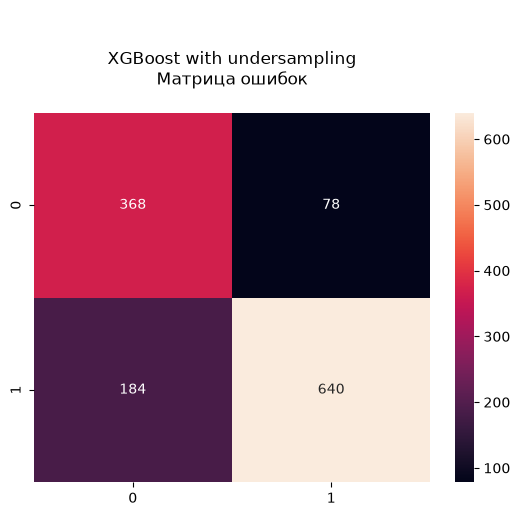

In [102]:
cm = confusion_matrix(y_val_t, xgb_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nXGBoost with undersampling\nМатрица ошибок\n')

Out[103]: Text(0.5, 1.0, '\n\nXGBoost with oversampling\nМатрица ошибок\n')


Text(0.5, 1.0, '\n\nXGBoost with oversampling\nМатрица ошибок\n')

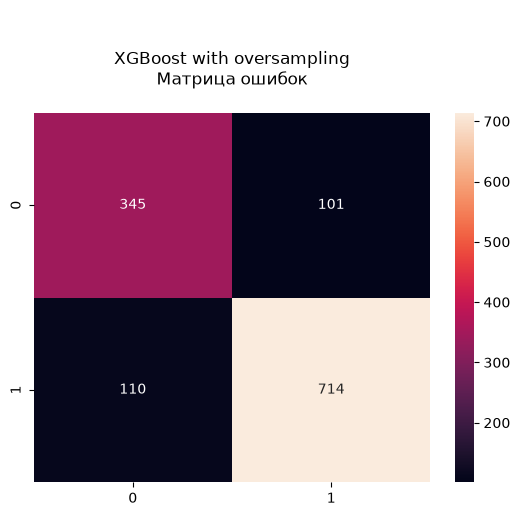

In [103]:
cm_ros = confusion_matrix(y_val_t, xgb_ros_pred)
sns.heatmap(cm_ros, annot=True, fmt='d').set_title('\n\nXGBoost with oversampling\nМатрица ошибок\n')

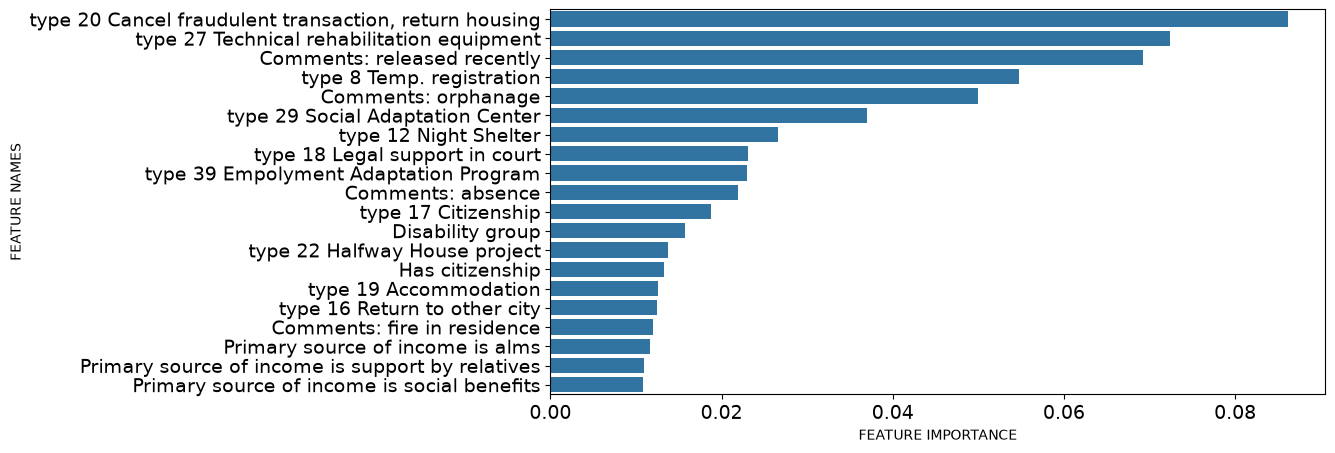

In [104]:
plot_feature_importance(xgb.feature_importances_, x_columns_t, 'XGBOOST undersampling ')

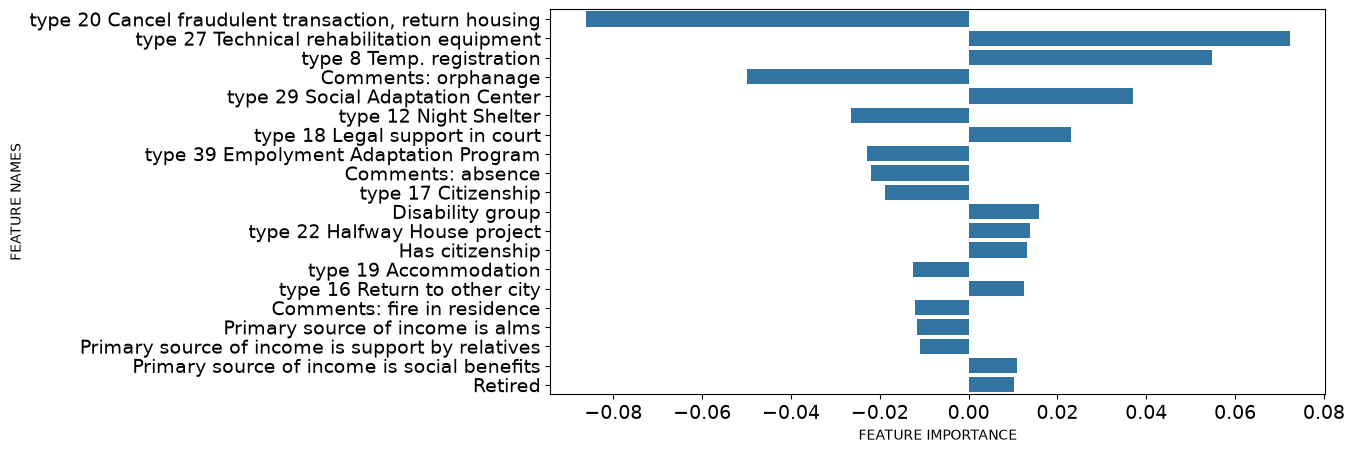

In [105]:
plot_icicle(xgb, x_columns_t, xgb.feature_importances_)

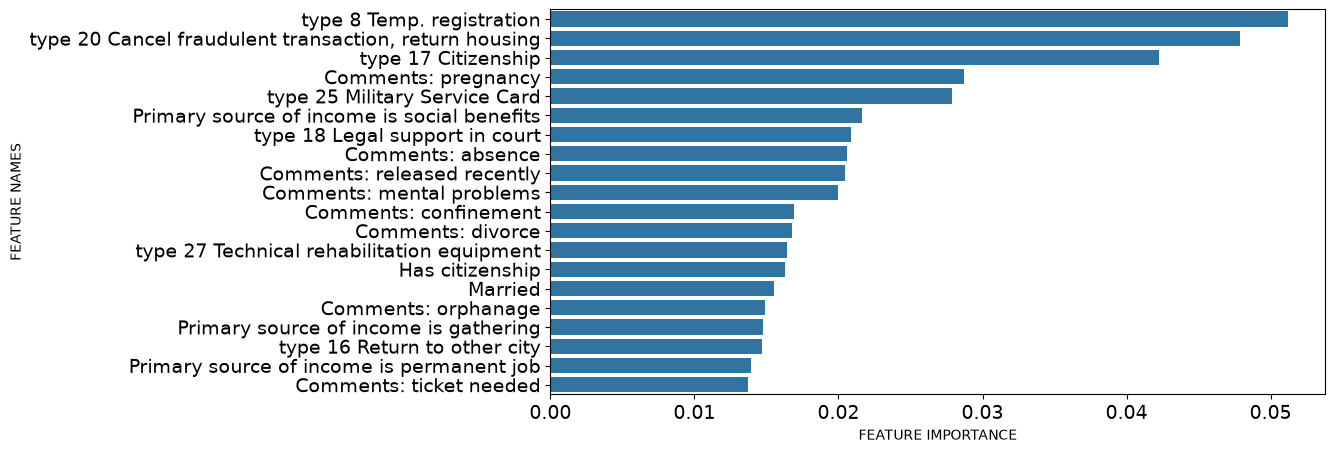

In [106]:
plot_feature_importance(xgb_ros.feature_importances_, x_columns_t, 'XGBOOST oversampling ')

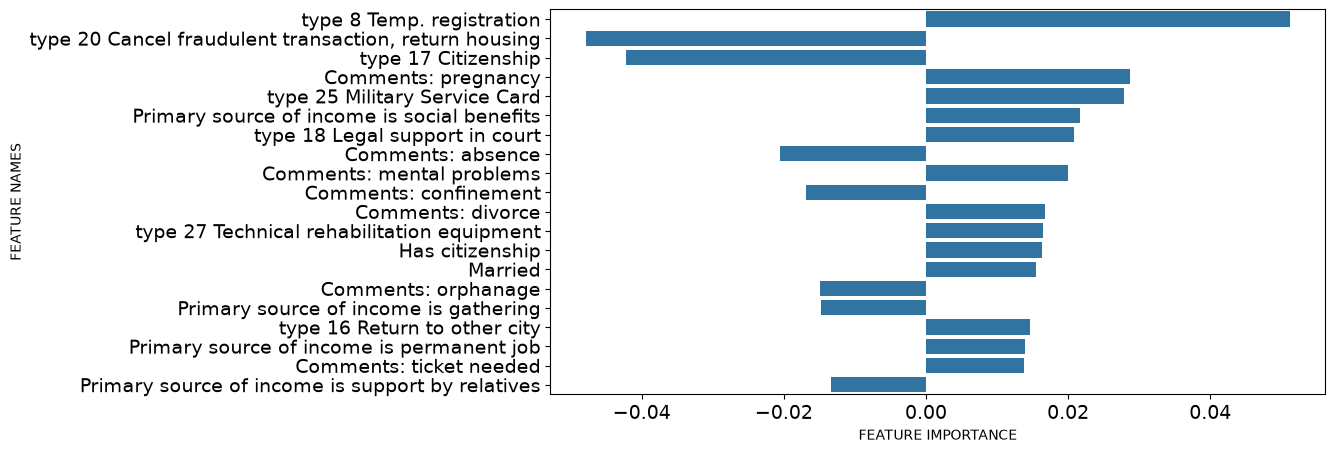

In [107]:
plot_icicle(xgb_ros, x_columns_t, xgb_ros.feature_importances_)

## CatBoost

### From file

In [108]:
cb = CatBoostClassifier(random_state=SEED)
cb_ros = CatBoostClassifier(random_state=SEED)

In [109]:
cb.load_model('cb.model')
cb_ros.load_model('cb_ros.model')

Out[109]: CatBoostClassifier(loss_function='Logloss', random_seed=42, verbose=0)


CatBoostClassifier(loss_function='Logloss', random_seed=42, verbose=0)

MSE = 0.24330708661417322
Accuracy = 0.7566929133858268
Precision = 0.7378640776699029
Recall = 0.8673323823109843
F1 Score = 0.7973770491803279
              precision    recall  f1-score   support

unsuccessful       0.62      0.79      0.70       446
  successful       0.87      0.74      0.80       824

    accuracy                           0.76      1270
   macro avg       0.74      0.76      0.75      1270
weighted avg       0.78      0.76      0.76      1270

Out[110]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x123502e90>


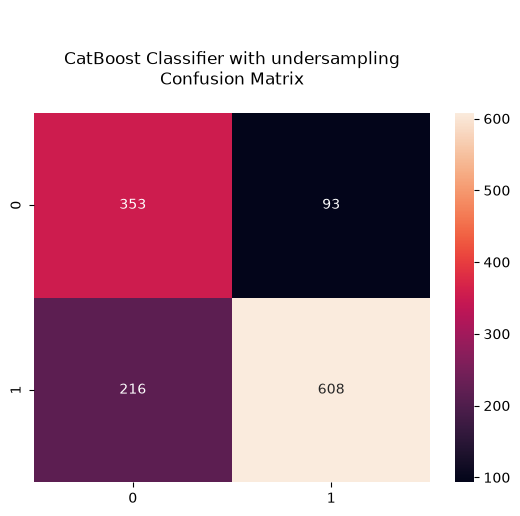

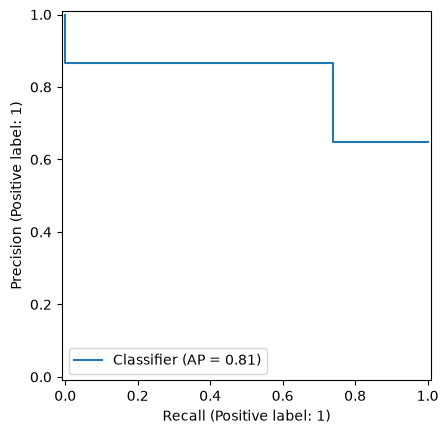

In [110]:
cb_pred = cb.predict(X_val_t)
print('MSE =', mean_squared_error(cb_pred, y_val_t))
print('Accuracy =', accuracy_score(cb_pred, y_val_t))
print('Precision =', precision_score(cb_pred, y_val_t))
print('Recall =', recall_score(cb_pred, y_val_t))
print('F1 Score =', f1_score(cb_pred, y_val_t))

print(classification_report(y_val_t, cb_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, cb_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nCatBoost Classifier with undersampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, cb_pred)

MSE = 0.21653543307086615
Accuracy = 0.7834645669291339
Precision = 0.7949029126213593
Recall = 0.8607095926412615
F1 Score = 0.8264984227129337
              precision    recall  f1-score   support

unsuccessful       0.67      0.76      0.71       446
  successful       0.86      0.79      0.83       824

    accuracy                           0.78      1270
   macro avg       0.76      0.78      0.77      1270
weighted avg       0.79      0.78      0.79      1270

Out[111]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x141269b90>


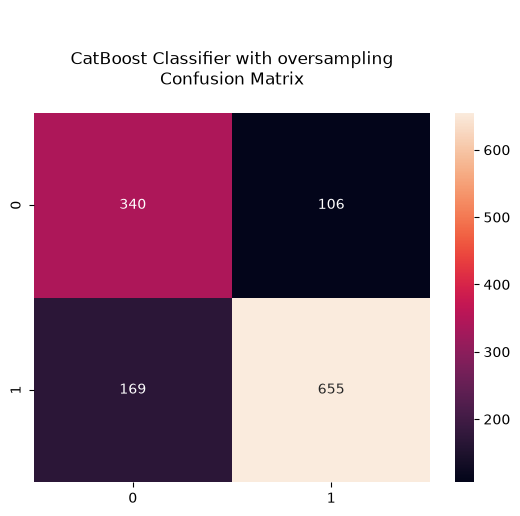

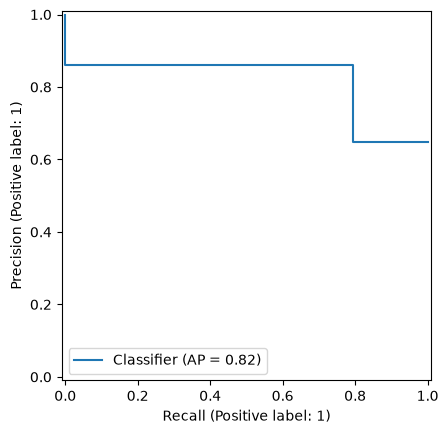

In [111]:
cb_ros_pred = cb_ros.predict(X_val_t)
print('MSE =', mean_squared_error(cb_ros_pred, y_val_t))
print('Accuracy =', accuracy_score(cb_ros_pred, y_val_t))
print('Precision =', precision_score(cb_ros_pred, y_val_t))
print('Recall =', recall_score(cb_ros_pred, y_val_t))
print('F1 Score =', f1_score(cb_ros_pred, y_val_t))

print(classification_report(y_val_t, cb_ros_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, cb_ros_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nCatBoost Classifier with oversampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, cb_ros_pred)

Results seem identical. Probably, the same file was saved under different names.

MSE = 0.24488188976377953
Accuracy = 0.7551181102362204
Precision = 0.7342233009708737
Recall = 0.8680057388809183
F1 Score = 0.7955292570677186
              precision    recall  f1-score   support

unsuccessful       0.62      0.79      0.69       446
  successful       0.87      0.73      0.80       824

    accuracy                           0.76      1270
   macro avg       0.74      0.76      0.75      1270
weighted avg       0.78      0.76      0.76      1270

Out[112]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x14184f410>


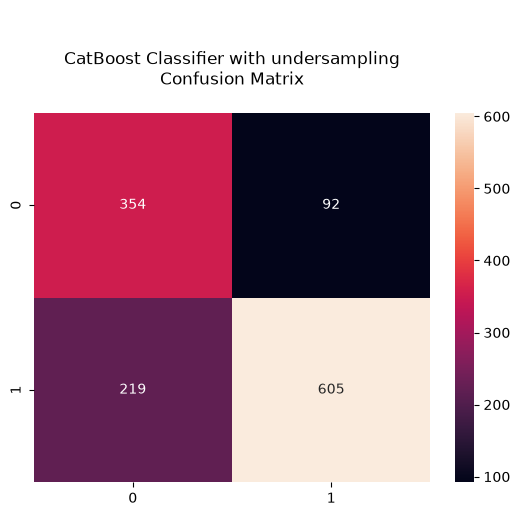

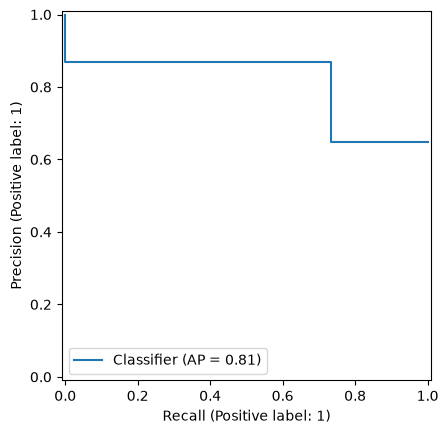

In [112]:
cb = CatBoostClassifier(random_state=SEED)
cb.fit(X_res_train_t, y_res_train_t, verbose=0)
cb_pred = cb.predict(X_val_t)
print('MSE =', mean_squared_error(cb_pred, y_val_t))
print('Accuracy =', accuracy_score(cb_pred, y_val_t))
print('Precision =', precision_score(cb_pred, y_val_t))
print('Recall =', recall_score(cb_pred, y_val_t))
print('F1 Score =', f1_score(cb_pred, y_val_t))

print(classification_report(y_val_t, cb_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, cb_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nCatBoost Classifier with undersampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, cb_pred)

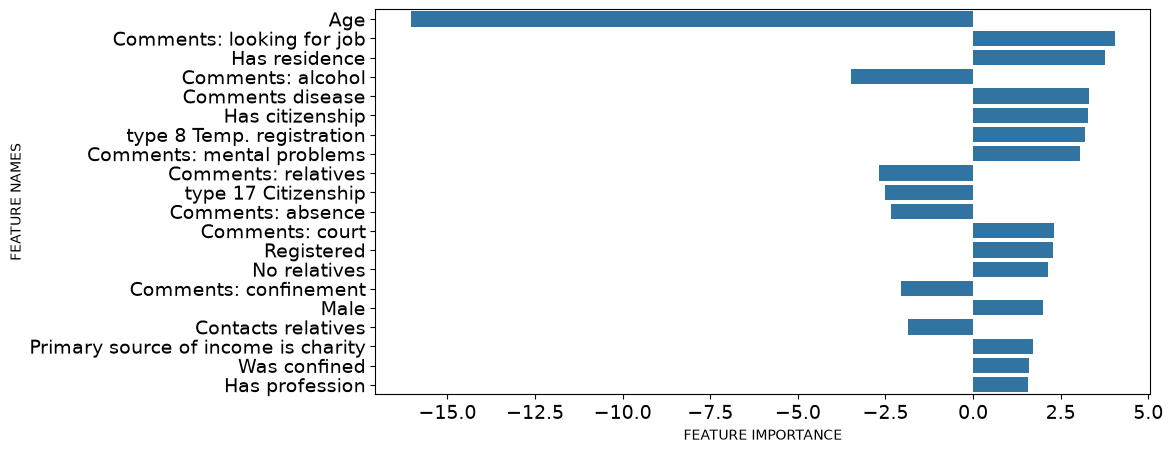

In [113]:
plot_icicle(cb, x_columns_t, cb.get_feature_importance())

MSE = 0.2173228346456693
Accuracy = 0.7826771653543307
Precision = 0.7985436893203883
Recall = 0.8567708333333334
F1 Score = 0.8266331658291457
              precision    recall  f1-score   support

unsuccessful       0.67      0.75      0.71       446
  successful       0.86      0.80      0.83       824

    accuracy                           0.78      1270
   macro avg       0.76      0.78      0.77      1270
weighted avg       0.79      0.78      0.79      1270

Out[114]: <sklearn.metrics._plot.precision_recall_curve.PrecisionRecallDisplay at 0x141d10f90>


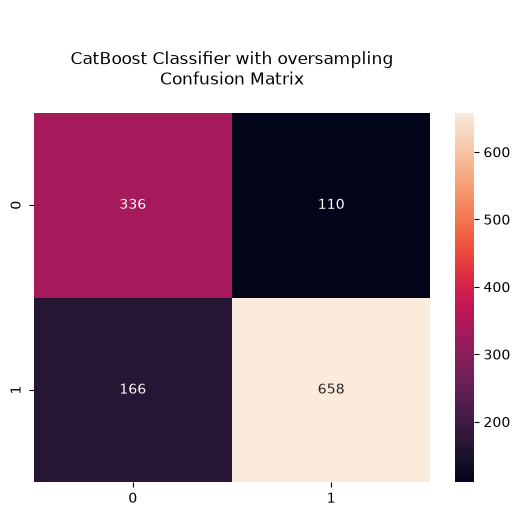

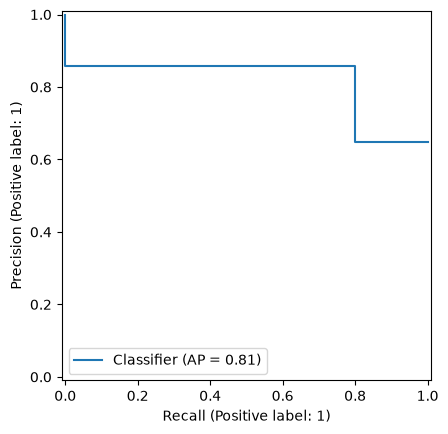

In [114]:
cb_ros = CatBoostClassifier(random_state=SEED)
cb_ros.fit(X_ros_train_t, y_ros_train_t, verbose=0)
cb_ros_pred = cb_ros.predict(X_val_t)
print('MSE =', mean_squared_error(cb_ros_pred, y_val_t))
print('Accuracy =', accuracy_score(cb_ros_pred, y_val_t))
print('Precision =', precision_score(cb_ros_pred, y_val_t))
print('Recall =', recall_score(cb_ros_pred, y_val_t))
print('F1 Score =', f1_score(cb_ros_pred, y_val_t))

print(classification_report(y_val_t, cb_ros_pred, target_names=['unsuccessful', 'successful']))

cm = confusion_matrix(y_val_t, cb_ros_pred)
sns.heatmap(cm, annot=True, fmt='d').set_title('\n\nCatBoost Classifier with oversampling\nConfusion Matrix\n')

PrecisionRecallDisplay.from_predictions(y_val_t, cb_ros_pred)

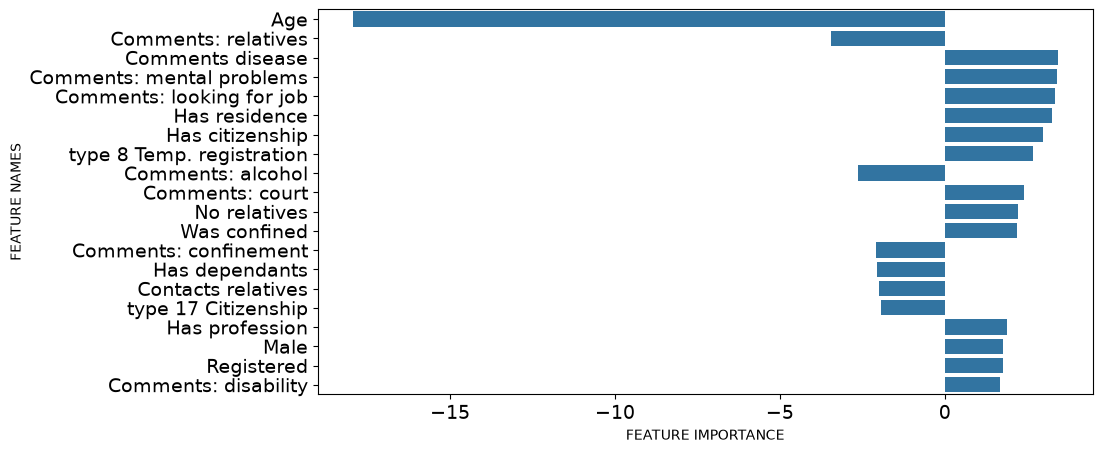

In [115]:
plot_icicle(cb_ros, x_columns_t, cb_ros.get_feature_importance())

## Typical client

### Client with no data (all NaNs)

In [116]:
no_client_t = pd.DataFrame(np.nan, index=[0], columns=x_columns_t)

In [117]:
#no_client_t.to_csv('no_client.csv', index=False)

In [118]:
#no_client_t = pd.read_csv('no_client.csv')

### Client with averaged data (with NaNs)

Seems like only age can be averaged, the rest needs to be replaced with the most frequent value.

In [119]:
typical_client_t = no_client_t.copy()
typical_client_t.age = with_onehot_types.age.mean()
typical_client_t.age

Out[119]: 
0    50.410812
Name: age, dtype: float64


0    50.410812
Name: age, dtype: float64

In [120]:
ones = []
zeros = []
for column in X_t.columns:
    if column != 'age' and column != 'disability_group' and column != 'released_recently' and not column.startswith('type_'):
        vc = X_t[column].value_counts()
        c0 = vc.get(0, 0)
        c1 = vc.get(1, 0)
        if c0 == max(c0, c1, X_t.shape[0] - c0 - c1):
            zeros.append(column)
        elif c1 == max(c0, c1, X_t.shape[0] - c0 - c1):
            ones.append(column)
ones

Out[120]: ['gender', 'is_homeless']


['gender', 'is_homeless']

In [121]:
zeros

Out[121]: 
['no_birthdate',
 'is_married',
 'has_dependants',
 'has_residence',
 'comments_alcohol',
 'comments_chem',
 'comments_disability',
 'comments_absence',
 'comments_orphange',
 'comments_work',
 'comments_confinement',
 'comments_noresidence',
 'comments_aggression',
 'comments_disturbance',
 'comments_disease',
 'comments_death',
 'comments_nursinghome',
 'comments_relatives',
 'comments_illiteracy',
 'comments_foreigner',
 'comments_ticket',
 'comments_court',
 'comments_pregnancy',
 'comments_mental',
 'comments_fire',
 'comments_social_benefits',
 'comments_divorce',
 'contacts_relatives',
 'no_relatives']


['no_birthdate', 'is_married', 'has_dependants', 'has_residence', 'comments_alcohol', 'comments_chem', 'comments_disability', 'comments_absence', 'comments_orphange', 'comments_work', 'comments_confinement', 'comments_noresidence', 'comments_aggression', 'comments_disturbance', 'comments_disease', 'comments_death', 'comments_nursinghome', 'comments_relatives', 'comments_illiteracy', 'comments_foreigner', 'comments_ticket', 'comments_court', 'comments_pregnancy', 'comments_mental', 'comments_fire', 'comments_social_benefits', 'comments_divorce', 'contacts_relatives', 'no_relatives']

In [122]:
typical_client_t[ones] = 1
typical_client_t[zeros] = 0

In [123]:
#typical_client_t.to_csv('typical_client.csv', index=False)

In [124]:
#typical_client_t = pd.read_csv('typical_client_with_nans.csv')

Contract types are NaNs here, which is not in line with the dataset logic. Better set them all to zeros.

In [125]:
typical_client_t.type_17

Out[125]: 
0   NaN
Name: type_17, dtype: float64


0   NaN
Name: type_17, dtype: float64

In [126]:
types = [c for c in X_t.columns if c.startswith('type_')]
len(types)

Out[126]: 43


43

In [127]:
typical_client_t[types] = 0

In [128]:
# typical_client_t.to_csv("typical_client_with_nans.csv", index = False)

### Typical client without NaNs (to evaluate models that don't eat NaNs)

In [129]:
typical_client_nonans = typical_client_t.fillna(0)
typical_client_nonans.isna().any().sum()

Out[129]: np.int64(0)


np.int64(0)

In [130]:
# typical_client_nonans.to_csv("typical_client_without_nans.csv", index=False)